<div align="center">

# PlanificaIA

## Sistema multi-agente para la planificación de estudio personalizada

**Semana 9 · Hackathon 7 — Implementación de un sistema multi-agente**

|                       |                                                                                                                                                                           |
| --------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Equipo**            | NAN                                                                                                                                                                       |
| **Integrantes**       | Aguinaga Pizarro, Bianca Brunella<br>González Vidalón, Ian Steve<br>Meza Torres, Fabryzzio Jossue<br>Monja Castro, Jeffrey Antonio<br>Navarro Mendoza, Aaron Cesar Aldair |
| **Caso seleccionado** | Caso 1 — Planificador de estudio personalizado                                                                                                                            |
| **Framework**         | CrewAI (orquestación de agentes) + Ollama (LLM local) · compatible con Groq                                                                                               |
| **Fecha de entrega**  | 13 de octubre de 2026                                                                                                                                                     |

</div>

---

### Contenido

1. [Introducción del caso](#6.2-Introducción-del-caso)
2. [Diseño de agentes](#6.3-Diseño-de-agentes)
3. [Diseño del flujo de orquestación](#6.4-Diseño-del-flujo-de-orquestación)
4. [Implementación](#6.5-Implementación-con-CrewAI-+-Ollama-/-Groq)
5. [Resultados intermedios](#6.6-Resultados-intermedios)
6. [Decisión final](#6.7-Decisión-final)
7. [Evaluación crítica](#6.8-Evaluación-crítica)
8. [Conclusiones](#Conclusiones)


## 6.2 Introducción del caso

**¿Cuál es el problema?**
Un estudiante universitario lleva 5 cursos con distinta dificultad, créditos y fechas de evaluación, y tiene un tiempo libre fragmentado por clases, un trabajo de medio tiempo y traslados. Cada semana debe decidir **cuántas horas dedicar a cada curso, en qué día y en qué franja**. Hoy esa decisión se toma "a ojo": se estudia lo más urgente o lo que más gusta, y los cursos críticos quedan relegados hasta la víspera del examen.

**¿Por qué es importante?**

- La mala distribución del tiempo es una de las principales causas de bajo rendimiento y de desaprobación en los primeros ciclos.
- Concentrar el estudio en la noche anterior aumenta el estrés y reduce la retención (frente a la práctica espaciada).
- Un plan que no respeta la disponibilidad real **no se cumple**: el problema no es solo priorizar, sino priorizar dentro de restricciones.

**¿Qué decisión se busca apoyar?**
Elegir **un plan semanal de estudio** (sesiones con día, hora, curso y actividad) entre varias alternativas, de modo que:

1. priorice los cursos en riesgo y las evaluaciones cercanas,
2. respete las restricciones duras (bloques libres, máximo de horas por día, fechas límite), y
3. sea sostenible (balance de carga, descanso y preferencias personales).

**¿Quién usará este sistema?**

- **Usuario principal:** el estudiante, que recibe un plan semanal justificado.
- **Usuarios secundarios:** tutores o consejeros académicos, que pueden usarlo para preparar sesiones de acompañamiento a alumnos en riesgo.

**¿Qué impacto tendría?**

- Menos tiempo decidiendo _qué estudiar_ y más tiempo estudiando.
- Detección temprana de cursos en riesgo (p. ej., nota actual 11 en un curso de dificultad 5).
- Planes **verificables**: cada propuesta pasa por un auditor que comprueba con código que el plan es realizable.

**Criterios de decisión** (definidos por el equipo y usados por el agente evaluador):

| Criterio            | Peso | Pregunta que responde                                                               |
| ------------------- | ---- | ----------------------------------------------------------------------------------- |
| Prioridad académica | 30 % | ¿Dedica suficientes horas, a tiempo, a los cursos críticos y evaluaciones cercanas? |
| Factibilidad        | 25 % | ¿Cumple las restricciones duras (bloques, horas/día, fechas límite)?                |
| Balance de carga    | 20 % | ¿Distribuye el esfuerzo sin picos excesivos?                                        |
| Bienestar           | 15 % | ¿Evita sobrecarga y sesiones demasiado largas?                                      |
| Preferencias        | 10 % | ¿Respeta preferencias del estudiante (p. ej., cursos difíciles en la mañana)?       |


## 6.3 Diseño de agentes

El sistema tiene **5 agentes**: los 4 recomendados en el enunciado más un **Auditor de factibilidad** que propusimos como agente adicional.

| #   | Agente                                       | Rol                            | Objetivo                                                       | Qué recibe                                                                                                                         | Qué produce                                                                                                                            |
| --- | -------------------------------------------- | ------------------------------ | -------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------- |
| 1   | **Analista del estudiante**                  | Experto en análisis académico  | Entender contexto, restricciones y prioridades                 | Perfil del estudiante (cursos, notas, evaluaciones, disponibilidad, restricciones)                                                 | Resumen estructurado: prioridades, riesgos, horas disponibles, datos faltantes                                                         |
| 2   | **Planificador**                             | Diseñador de planes de estudio | Generar alternativas de planificación                          | Análisis + tabla de apoyo (franjas libres y cursos permitidos en cada una) + retroalimentación del auditor si hay re-planificación | **3 planes semanales**, uno por enfoque (urgencia, balance, riesgo): asignación franja → curso → actividad en JSON validado (Pydantic) |
| 3   | **Auditor de factibilidad** ⭐ _(adicional)_ | Verificador de restricciones   | Comprobar que cada plan sea realizable y decir cómo corregirlo | Planes + **reporte de verificación calculado en Python** (métricas, violaciones y sugerencias)                                     | Veredicto por plan (APTO / CON OBSERVACIONES / NO APTO) + instrucciones de corrección                                                  |
| 4   | **Evaluador**                                | Evaluador de carga académica   | Comparar planes con criterios ponderados                       | Análisis + planes + métricas + auditoría                                                                                           | Puntajes 1–5 por criterio, ventajas y desventajas (JSON)                                                                               |
| 5   | **Decisor**                                  | Asesor académico               | Recomendar el mejor plan                                       | Todo lo anterior + puntaje ponderado                                                                                               | Decisión final justificada, riesgos, puntos de revisión humana y horario final                                                         |

### ¿Por qué un agente adicional (Auditor de factibilidad)?

En las primeras pruebas observamos que el planificador (un LLM) **propone sesiones fuera de los bloques libres, suma mal las horas o programa estudio después de la evaluación**. Los LLM no son confiables haciendo aritmética de horarios. Si esos errores llegan al evaluador, este puede premiar un plan que en la práctica es imposible de cumplir.

El Auditor resuelve esto con un diseño **híbrido**:

1. **Verificación determinista (Python):** calcula horas por día y por curso, detecta solapamientos, sesiones fuera de bloque, violación de fechas límite y cursos por debajo de su mínimo, y propone **sugerencias de corrección** sobre las franjas. Esto es exacto y reproducible.
2. **Interpretación (LLM):** traduce el reporte en un veredicto y en **instrucciones concretas de corrección** ("mover la sesión de Ética del miércoles al lunes 20:00–21:00").

Además, el auditor habilita un **bucle de corrección**: los planes con violaciones duras vuelven al planificador con la retroalimentación (máximo 3 rondas); los planes aptos se conservan. Así, el evaluador y el decisor trabajan sobre planes que ya fueron verificados, y las métricas exactas sirven como evidencia objetiva para puntuar.

### Separación de responsabilidades

- Ningún agente hace el trabajo de otro: el analista **no propone horarios**, el planificador **no evalúa**, el evaluador **no calcula el puntaje final** (lo hace Python con los pesos definidos) y el decisor **no inventa planes nuevos**.
- Cada agente usa una **temperatura** acorde a su tarea: baja (0.1–0.2) para analizar, auditar, evaluar y decidir; más alta (0.5) para que el planificador genere alternativas diversas, y 0.2 cuando el planificador **corrige** un plan (queremos cambios mínimos, no un plan nuevo).


## 6.4 Diseño del flujo de orquestación

**Tipo de flujo:** **secuencial con un bucle condicional de corrección** (iterativo acotado).

| Paso | Agente                                    | Entrada                                               | Salida que pasa al siguiente                                                                                                                      |
| ---- | ----------------------------------------- | ----------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1    | Analista                                  | Perfil del estudiante (JSON)                          | `analisis` (Markdown)                                                                                                                             |
| 2    | Planificador (×3, un enfoque por llamada) | `analisis` + `tabla_apoyo`                            | `planes` (3 planes en JSON Pydantic)                                                                                                              |
| 3a   | Verificador Python                        | `planes` + perfil                                     | `reporte` (métricas y violaciones duras)                                                                                                          |
| 3b   | Auditor (×1 por plan)                     | cada plan + su `reporte`                              | `informe_auditor` (veredicto + correcciones por plan)                                                                                             |
| ↺    | _Condición_                               | ¿algún plan con violaciones duras **y** rondas < 3?   | Sí → **solo los planes NO APTOS** vuelven al paso 2 (modo corrección, temperatura 0.2) con sus violaciones, sugerencias y su informe de auditoría |
| 4    | Evaluador                                 | `analisis` + `planes` + `reporte` + `informe_auditor` | `evaluacion` (puntajes 1–5 por criterio)                                                                                                          |
| 4b   | Python                                    | `evaluacion` + pesos                                  | `puntajes` ponderados y ranking                                                                                                                   |
| 5    | **Decisor (integrador)**                  | Todo lo anterior                                      | **Decisión final** + horario                                                                                                                      |
| 6    | Persona                                   | Decisión                                              | Validación humana antes de aplicar                                                                                                                |

- **Quién integra la respuesta final:** el **Decisor** (Asesor académico) es el único que ve todas las salidas y produce la recomendación.
- **Por qué la condición del bucle la decide Python y no un LLM:** así el bucle es predecible (no depende de que un modelo "opine" que el plan está bien) y está acotado a 3 rondas para controlar costo y tiempo.
- **Implementación:** cada paso se ejecuta como una `Crew` de CrewAI con un agente y una tarea; un **orquestador en Python** encadena las salidas (vía `inputs` interpolados en los prompts) y evalúa la condición del bucle.

```mermaid
flowchart TD
    D[/"Perfil del estudiante"/] --> A1["1 · Analista del estudiante"]
    A1 -- análisis --> A2["2 · Planificador"]
    A2 -- "3 planes (JSON)" --> V["3a · Verificador Python"]
    V -- reporte --> A3["3b · Auditor de factibilidad ⭐"]
    A3 --> C{"¿Violaciones duras<br/>y ronda < 3?"}
    C -- "Sí: planes NO APTOS + retroalimentación" --> A2
    C -- No --> A4["4 · Evaluador de carga"]
    A4 -- "puntajes 1–5" --> P["4b · Puntaje ponderado (Python)"]
    P --> A5["5 · Decisor / Asesor académico"]
    A5 --> F[/"Plan recomendado + riesgos"/]
    F --> H(["Revisión humana"])
```

El mismo diagrama se genera como imagen (`diagrama_flujo.png`) en la siguiente celda, para que se vea en cualquier visor y pueda usarse en la presentación.


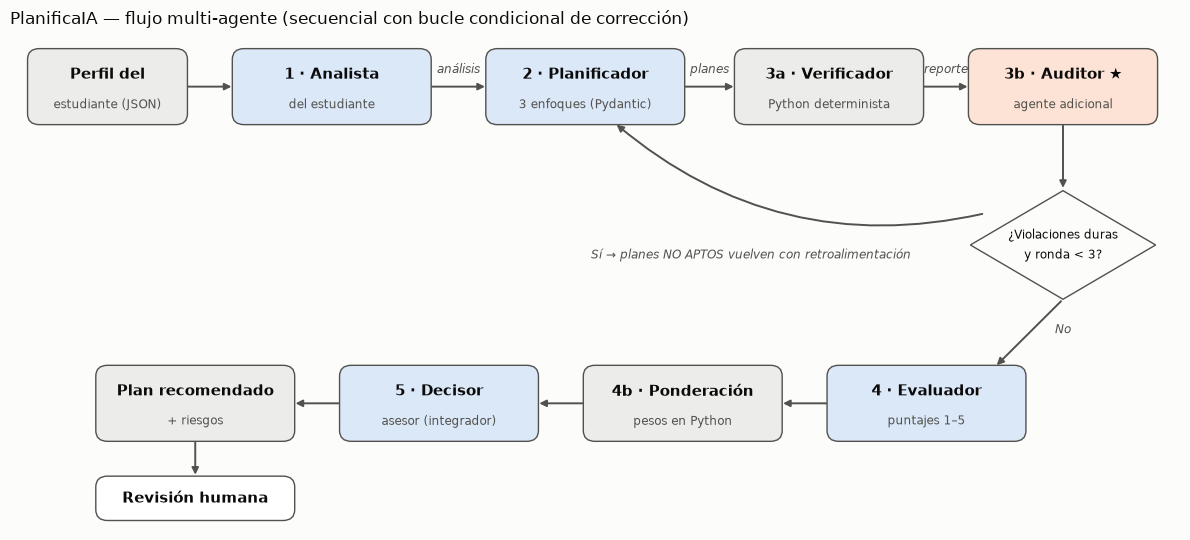

In [1]:
# Diagrama del flujo multi-agente (se guarda como PNG para la presentación)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon

TINTA, TINTA_2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
COLOR_AGENTE, COLOR_PY, COLOR_EXTRA = "#dbe8f8", "#ececea", "#fde3d6"

fig, ax = plt.subplots(figsize=(12, 5.5), facecolor=FONDO)
ax.set_xlim(0, 12)
ax.set_ylim(0, 5.5)
ax.axis("off")


def caja(x, y, w, h, texto, color, sub=None):
    ax.add_patch(
        FancyBboxPatch(
            (x - w / 2, y - h / 2),
            w,
            h,
            boxstyle="round,pad=0.02,rounding_size=0.12",
            fc=color,
            ec=TINTA_2,
            lw=1,
        )
    )
    ax.text(
        x,
        y + (0.13 if sub else 0),
        texto,
        ha="center",
        va="center",
        fontsize=10.5,
        color=TINTA,
        weight="bold",
    )
    if sub:
        ax.text(x, y - 0.2, sub, ha="center", va="center", fontsize=8.5, color=TINTA_2)


def flecha(x1, y1, x2, y2, texto=None, curva=0.0, dx=0, dy=0.15):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="-|>", color=TINTA_2, lw=1.4, connectionstyle=f"arc3,rad={curva}"
        ),
    )
    if texto:
        ax.text(
            (x1 + x2) / 2 + dx,
            (y1 + y2) / 2 + dy,
            texto,
            ha="center",
            fontsize=8.5,
            color=TINTA_2,
            style="italic",
        )


# Fila superior: datos -> analista -> planificador -> verificador -> auditor
caja(1.0, 4.9, 1.6, 0.8, "Perfil del", COLOR_PY, "estudiante (JSON)")
caja(3.3, 4.9, 2.0, 0.8, "1 · Analista", COLOR_AGENTE, "del estudiante")
caja(5.9, 4.9, 2.0, 0.8, "2 · Planificador", COLOR_AGENTE, "3 enfoques (Pydantic)")
caja(8.4, 4.9, 1.9, 0.8, "3a · Verificador", COLOR_PY, "Python determinista")
caja(10.8, 4.9, 1.9, 0.8, "3b · Auditor ★", COLOR_EXTRA, "agente adicional")
flecha(1.8, 4.9, 2.3, 4.9)
flecha(4.3, 4.9, 4.9, 4.9, "análisis")
flecha(6.9, 4.9, 7.45, 4.9, "planes")
flecha(9.35, 4.9, 9.85, 4.9, "reporte")

# Decisión condicional
rombo = Polygon(
    [[10.8, 3.75], [11.75, 3.15], [10.8, 2.55], [9.85, 3.15]],
    closed=True,
    fc=FONDO,
    ec=TINTA_2,
    lw=1,
)
ax.add_patch(rombo)
ax.text(10.8, 3.22, "¿Violaciones duras", ha="center", fontsize=8.5, color=TINTA)
ax.text(10.8, 3.0, "y ronda < 3?", ha="center", fontsize=8.5, color=TINTA)
flecha(10.8, 4.5, 10.8, 3.75)
flecha(10.0, 3.5, 6.2, 4.5, curva=-0.25)
ax.text(
    7.6,
    3.0,
    "Sí → planes NO APTOS vuelven con retroalimentación",
    ha="center",
    fontsize=8.5,
    color=TINTA_2,
    style="italic",
)

# Fila inferior: evaluador -> puntaje -> decisor -> salida -> humano
caja(9.4, 1.4, 2.0, 0.8, "4 · Evaluador", COLOR_AGENTE, "puntajes 1–5")
caja(6.9, 1.4, 2.0, 0.8, "4b · Ponderación", COLOR_PY, "pesos en Python")
caja(4.4, 1.4, 2.0, 0.8, "5 · Decisor", COLOR_AGENTE, "asesor (integrador)")
caja(1.9, 1.4, 2.0, 0.8, "Plan recomendado", COLOR_PY, "+ riesgos")
flecha(10.8, 2.55, 10.1, 1.8, "No", dx=0.35, dy=0.0)
flecha(8.4, 1.4, 7.9, 1.4)
flecha(5.9, 1.4, 5.4, 1.4)
flecha(3.4, 1.4, 2.9, 1.4)
caja(1.9, 0.35, 2.0, 0.45, "Revisión humana", "#ffffff")
flecha(1.9, 1.0, 1.9, 0.58)

ax.set_title(
    "PlanificaIA — flujo multi-agente (secuencial con bucle condicional de corrección)",
    fontsize=12.5,
    color=TINTA,
    loc="left",
    pad=6,
)
plt.tight_layout()
plt.savefig("diagrama_flujo.png", dpi=180, facecolor=FONDO, bbox_inches="tight")
plt.show()

## 6.5 Implementación con CrewAI + Ollama / Groq

### 6.5.1 Configuración del entorno

**Framework de agentes: CrewAI.** Cada agente se define con `role`, `goal` y `backstory` (su _system prompt_), y cada tarea con `description` y `expected_output`. CrewAI se encarga de construir los mensajes, llamar al LLM y validar salidas estructuradas con Pydantic.

**Motor de lenguaje:** el notebook funciona con dos proveedores, seleccionables con una variable:

| Proveedor                | Modelo                                   | Cuándo usarlo                                                                              |
| ------------------------ | ---------------------------------------- | ------------------------------------------------------------------------------------------ |
| `ollama` _(por defecto)_ | `qwen2.5:7b` con contexto de 16 K tokens | Ejecución **local**, sin costo ni API key; es el entorno que usamos en clase               |
| `groq`                   | `llama-3.3-70b-versatile`                | Ejecución en la nube, mucho más rápida y con un modelo más grande; requiere `GROQ_API_KEY` |

**¿Por qué `qwen2.5:7b`?** Probamos los modelos que teníamos instalados localmente:

| Modelo              | Velocidad medida | Observación                                                                                          |
| ------------------- | ---------------- | ---------------------------------------------------------------------------------------------------- |
| `gpt-oss:20b`       | ~2 tokens/s      | Inviable para un flujo de más de 10 llamadas en nuestra laptop (24 GB de RAM compartida)             |
| `qwen2.5-coder:14b` | ~12 tokens/s     | Usable, pero cuando escribía las horas libremente cometía los mismos errores de horario que el de 7B |
| **`qwen2.5:7b`**    | ~40 tokens/s     | Rápido, buen español y JSON válido de forma consistente                                              |

La lección fue que **la calidad de los planes dependía más del diseño del sistema que del tamaño del modelo**: lo que redujo los errores fue darle al planificador franjas válidas precalculadas y una retroalimentación accionable (ver 6.5.2 y 6.8). La menor capacidad de razonamiento del modelo de 7B es justamente lo que compensa el **Auditor de factibilidad**.

**Importante — ventana de contexto:** Ollama usa por defecto un contexto corto (≈4 K tokens) y **trunca en silencio** los prompts largos. Como el decisor recibe análisis + planes + auditoría + evaluación, creamos una variante del modelo con `num_ctx = 16384` mediante un `Modelfile`.

```bash
# Instalación (una sola vez)
pip install -U crewai pandas matplotlib python-dotenv
ollama pull qwen2.5:7b
```


In [1]:
import os

# Desactivamos telemetría/trazas remotas de CrewAI: el sistema corre 100 % local
os.environ["CREWAI_TELEMETRY_OPT_OUT"] = "true"
os.environ["OTEL_SDK_DISABLED"] = "true"
os.environ["CREWAI_TRACING_ENABLED"] = "false"

import json, math, re, time, subprocess, unicodedata, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import Optional

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pydantic import BaseModel, Field, field_validator, ValidationError
from crewai import Agent, Task, Crew, Process, LLM
import crewai

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
try:
    from dotenv import load_dotenv

    load_dotenv()  # lee GROQ_API_KEY / PROVEEDOR_LLM desde un archivo .env si existe
except ImportError:
    pass

SALIDAS = Path("salidas")
SALIDAS.mkdir(exist_ok=True)
print("CrewAI", crewai.__version__)

CrewAI 1.15.28


In [2]:
# ---- Selección del proveedor y modelo -------------------------------------------
PROVEEDOR = os.getenv("PROVEEDOR_LLM", "ollama")  # "ollama" (local) | "groq" (nube)
OLLAMA_URL = os.getenv("OLLAMA_HOST", "http://localhost:11434")
MODELO_BASE_OLLAMA = "qwen2.5:7b"
MODELO_OLLAMA = "qwen2.5-planifica"  # qwen2.5:7b + num_ctx 16384
MODELO_GROQ = "llama-3.3-70b-versatile"

if PROVEEDOR == "ollama":
    # Crea (una vez) la variante con contexto ampliado a partir de un Modelfile
    Path("Modelfile").write_text(f"FROM {MODELO_BASE_OLLAMA}\nPARAMETER num_ctx 4096\n")
    modelos = subprocess.run(["ollama", "list"], capture_output=True, text=True).stdout
    if MODELO_OLLAMA not in modelos:
        subprocess.run(
            ["ollama", "create", MODELO_OLLAMA, "-f", "Modelfile"], check=True
        )
    print(
        subprocess.run(
            ["ollama", "show", MODELO_OLLAMA], capture_output=True, text=True
        ).stdout
    )


def crear_llm(temperatura: float) -> LLM:
    # Devuelve el LLM configurado. Cada agente recibe su propia instancia con su temperatura.
    if PROVEEDOR == "groq":
        # Groq expone una API compatible con OpenAI
        return LLM(
            model=MODELO_GROQ,
            custom_openai=True,
            base_url="https://api.groq.com/openai/v1",
            api_key=os.environ["GROQ_API_KEY"],
            temperature=temperatura,
            max_tokens=4096,
        )
    return LLM(
        model=f"ollama/{MODELO_OLLAMA}", base_url=OLLAMA_URL, temperature=temperatura
    )


# Prueba de humo: el modelo responde
t0 = time.time()
respuesta = crear_llm(0.0).call("Responde solo con la palabra: LISTO")
print(f"Proveedor: {PROVEEDOR} | Respuesta: {respuesta!r} | {time.time() - t0:.1f} s")

  Model
    architecture        qwen2     
    parameters          7.6B      
    context length      32768     
    embedding length    3584      
    quantization        Q4_K_M    

  Capabilities
    completion    
    tools         

  Parameters
    num_ctx    4096    

  System
    You are Qwen, created by Alibaba Cloud. You are a helpful assistant.    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          


Proveedor: ollama | Respuesta: 'LISTO' | 6.4 s


### 6.5.2 Datos del caso: perfil del estudiante

Usamos un perfil **ficticio pero realista** de una estudiante de 5.º ciclo para la semana del **lunes 12 al domingo 18 de octubre de 2026**. Los datos se separan en:

- **Cursos:** créditos, dificultad (1–5), nota actual (0–20), próxima evaluación, horas sugeridas de estudio y prioridad percibida.
- **Disponibilidad:** bloques libres por día (ya descontadas clases, trabajo de medio tiempo y traslados).
- **Restricciones duras** (si se violan, el plan no es realizable) y **preferencias** (deseables).
- **Fechas límite** en formato estructurado para que el verificador pueda comprobarlas.


In [3]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

ESTUDIANTE = {
    "nombre": "Pedro (perfil ficticio)",
    "carrera": "Ciencia de Datos e IA, 5.º ciclo",
    "semana": "Lunes 12 al domingo 18 de octubre de 2026 (semana 9)",
    "objetivo_personal": "Subir Machine Learning de 11 a 14 o más y entregar a tiempo el proyecto de Estadística",
    "cursos": [
        {
            "curso": "Machine Learning",
            "creditos": 4,
            "dificultad": 2,
            "nota_actual": 11,
            "proxima_evaluacion": "Examen parcial el lunes 19/10 (semana siguiente)",
            "fecha_limite": None,
            "horas_sugeridas": 8,
            "prioridad_estudiante": "alta",
        },
        {
            "curso": "Estadística Inferencial",
            "creditos": 5,
            "dificultad": 5,
            "nota_actual": 13,
            "proxima_evaluacion": "Entrega de proyecto el viernes 16/10 a las 23:59",
            "fecha_limite": {"dia": "Viernes", "hora": "23:59"},
            "horas_sugeridas": 3,
            "prioridad_estudiante": "alta",
        },
    ],
    # Bloques libres para estudiar (fuera de clases, trabajo martes/jueves 14:00-18:00 y traslados)
    "disponibilidad": {
        "Sábado": [["09:00", "13:00"], ["16:00", "18:00"]],
        "Domingo": [["10:00", "13:00"]],
    },
    "max_horas_por_dia": 5,
    "restricciones_duras": [
        "Solo puede estudiar dentro de los bloques de disponibilidad indicados",
        "Máximo 5 horas de estudio por día",
        "No estudiar después de las 22:00",
        "El estudio de un curso debe terminar antes de su evaluación (fecha_limite)",
        "Los cursos con prioridad alta deben recibir al menos el 70 % de sus horas sugeridas, "
        "y los que tienen evaluación esta semana al menos el 50 %",
    ],
    "preferencias": [
        "Rinde mejor en la mañana: preferiría estudiar los cursos difíciles (dificultad 4-5) antes de las 13:00",
        "Sesiones de máximo 2 horas seguidas del mismo curso",
        "Quiere al menos un bloque libre el fin de semana para descansar",
    ],
}


def a_minutos(hhmm: str) -> int:
    h, m = hhmm.strip().split(":")
    return int(h) * 60 + int(m)


# Vista tabular de los datos de entrada
df_cursos = pd.DataFrame(ESTUDIANTE["cursos"]).drop(columns=["fecha_limite"])
horas_libres = {
    d: sum(a_minutos(f) - a_minutos(i) for i, f in b) / 60
    for d, b in ESTUDIANTE["disponibilidad"].items()
}
df_disp = pd.DataFrame(
    {
        "bloques libres": {
            d: ", ".join(f"{i}–{f}" for i, f in b)
            for d, b in ESTUDIANTE["disponibilidad"].items()
        },
        "horas libres": horas_libres,
    }
)
display(Markdown("**Cursos**"))
display(df_cursos)
display(Markdown("**Disponibilidad**"))
display(df_disp)
print(
    f"Horas sugeridas totales: {df_cursos.horas_sugeridas.sum()} h | Horas libres en la semana: {sum(horas_libres.values()):.0f} h"
)

**Cursos**

,curso,creditos,dificultad,nota_actual,proxima_evaluacion,horas_sugeridas,prioridad_estudiante
0,Machine Learning,4,2,11,Examen parcial el lunes 19/10 (semana siguiente),8,alta
1,Estadística Inferencial,5,5,13,Entrega de proyecto el viernes 16/10 a las 23:59,3,alta


**Disponibilidad**

,bloques libres,horas libres
Sábado,"09:00–13:00, 16:00–18:00",6.0
Domingo,10:00–13:00,3.0


Horas sugeridas totales: 11 h | Horas libres en la semana: 9 h


#### Datos derivados y tabla de apoyo (calculados con Python)

Los LLM pequeños **suman mal las horas** y les cuesta cruzar fechas límite con bloques libres. En vez de pedirles esa aritmética, la calculamos con código y se la entregamos como contexto:

- **Datos derivados** (horas libres por día y totales) → se agregan al perfil que recibe el Analista.
- **Franjas de estudio**: cada bloque libre se divide en franjas de hasta 2 h con un identificador (`F01`, `F02`, …) y, para cada franja, se listan los **cursos permitidos** (los que aún no tienen su evaluación en ese momento).
- **Tabla de apoyo** para el Planificador → horas objetivo y mínimo obligatorio por curso + las franjas.

Así el planificador **no inventa horarios**: decide _qué curso y qué actividad_ va en cada franja, que es la decisión realmente importante. Esto lo aprendimos en la primera versión del sistema (ver sección 6.8): cuando el LLM escribía las horas libremente, más de la mitad de los planes tenía sesiones fuera de los bloques libres o después de la evaluación.


In [4]:
def a_hhmm(minutos: int) -> str:
    return f"{minutos // 60:02d}:{minutos % 60:02d}"


def horas_minimas(curso: dict) -> float:
    # Restricción dura: prioridad alta -> 70 % de sus horas sugeridas; evaluación esta semana -> 50 %
    fraccion = (
        0.7
        if curso["prioridad_estudiante"] == "alta"
        else 0.5 if curso["fecha_limite"] else 0.0
    )
    return (
        math.ceil(curso["horas_sugeridas"] * fraccion * 2) / 2
    )  # redondeo a medias horas


def perfil_para_agentes(estudiante: dict) -> str:
    libres = {
        d: sum(a_minutos(f) - a_minutos(i) for i, f in b) / 60
        for d, b in estudiante["disponibilidad"].items()
    }
    derivados = {
        "horas_libres_por_dia": libres,
        "horas_libres_totales": sum(libres.values()),
        "horas_sugeridas_totales": sum(
            c["horas_sugeridas"] for c in estudiante["cursos"]
        ),
    }
    return json.dumps(
        {**estudiante, "datos_derivados_calculados_con_python": derivados},
        ensure_ascii=False,
        indent=1,
    )


def generar_franjas(estudiante: dict, max_horas: int = 2) -> list[dict]:
    # Divide cada bloque libre en franjas de hasta 2 h con un id (F01, F02, ...)
    franjas = []
    for d in DIAS:
        for a, b in estudiante["disponibilidad"].get(d, []):
            ini, fin = a_minutos(a), a_minutos(b)
            while ini < fin:
                corte = min(ini + max_horas * 60, fin)
                franjas.append(
                    {
                        "id": f"F{len(franjas) + 1:02d}",
                        "dia": d,
                        "inicio": a_hhmm(ini),
                        "fin": a_hhmm(corte),
                        "horas": (corte - ini) / 60,
                    }
                )
                ini = corte
    return franjas


def cursos_permitidos(franja: dict, estudiante: dict) -> list[str]:
    # Cursos cuya evaluación todavía no ocurrió al terminar la franja
    permitidos = []
    for c in estudiante["cursos"]:
        lim = c["fecha_limite"]
        if lim is None or (DIAS.index(franja["dia"]), a_minutos(franja["fin"])) <= (
            DIAS.index(lim["dia"]),
            a_minutos(lim["hora"]),
        ):
            permitidos.append(c["curso"])
    return permitidos


def tabla_apoyo(estudiante: dict) -> str:
    franjas = generar_franjas(estudiante)
    lineas = ["CURSOS (con las únicas franjas en las que se pueden estudiar):"]
    for c in estudiante["cursos"]:
        ids = [
            f["id"] for f in franjas if c["curso"] in cursos_permitidos(f, estudiante)
        ]
        lineas.append(
            f"- {c['curso']} (prioridad {c['prioridad_estudiante']}, dificultad {c['dificultad']}/5, "
            f"nota {c['nota_actual']}): objetivo {c['horas_sugeridas']} h, mínimo obligatorio {horas_minimas(c)} h. "
            f"Evaluación: {c['proxima_evaluacion']}. Franjas permitidas: {', '.join(ids)}"
        )
    lineas.append(
        "\nFRANJAS DISPONIBLES (id | día | horario | horas | cursos permitidos):"
    )
    for f in franjas:
        lineas.append(
            f"- {f['id']} | {f['dia']} | {f['inicio']}-{f['fin']} | {f['horas']:g} h | "
            + ", ".join(cursos_permitidos(f, estudiante))
        )
    lineas.append(
        f"\nLÍMITES: máximo {estudiante['max_horas_por_dia']} h de estudio por día; el plan debe sumar "
        "entre 18 y 22 h, es decir, usar entre 10 y 13 franjas (no todas)."
    )
    return "\n".join(lineas)


print(tabla_apoyo(ESTUDIANTE))

CURSOS (con las únicas franjas en las que se pueden estudiar):
- Machine Learning (prioridad alta, dificultad 2/5, nota 11): objetivo 8 h, mínimo obligatorio 6.0 h. Evaluación: Examen parcial el lunes 19/10 (semana siguiente). Franjas permitidas: F01, F02, F03, F04, F05
- Estadística Inferencial (prioridad alta, dificultad 5/5, nota 13): objetivo 3 h, mínimo obligatorio 2.5 h. Evaluación: Entrega de proyecto el viernes 16/10 a las 23:59. Franjas permitidas: 

FRANJAS DISPONIBLES (id | día | horario | horas | cursos permitidos):
- F01 | Sábado | 09:00-11:00 | 2 h | Machine Learning
- F02 | Sábado | 11:00-13:00 | 2 h | Machine Learning
- F03 | Sábado | 16:00-18:00 | 2 h | Machine Learning
- F04 | Domingo | 10:00-12:00 | 2 h | Machine Learning
- F05 | Domingo | 12:00-13:00 | 1 h | Machine Learning

LÍMITES: máximo 5 h de estudio por día; el plan debe sumar entre 18 y 22 h, es decir, usar entre 10 y 13 franjas (no todas).


### 6.5.3 Salidas estructuradas (Pydantic)

El planificador y el evaluador devuelven **JSON validado con Pydantic** en vez de texto libre. Esto permite:

- que el verificador en Python lea los planes sin ambigüedad (día, hora de inicio/fin, curso),
- graficar los planes y calcular el puntaje ponderado con código, y
- detectar de inmediato salidas mal formadas (si el JSON no valida, se reintenta).

El planificador devuelve una `PropuestaPlan` (franja → curso → actividad) que se convierte de forma determinista en un `PlanSemanal` (sesiones con día y hora). Los validadores normalizan errores menores del LLM (p. ej., `"miercoles"` → `"Miércoles"`, `"9:00"` → `"09:00"`, `"F3"` → `"F03"`).


In [5]:
def _sin_tildes(s: str) -> str:
    return (
        "".join(
            c
            for c in unicodedata.normalize("NFD", s)
            if unicodedata.category(c) != "Mn"
        )
        .lower()
        .strip()
    )


_DIA_CANONICO = {_sin_tildes(d): d for d in DIAS}


class Sesion(BaseModel):
    dia: str = Field(
        description="Día de la semana: Lunes, Martes, Miércoles, Jueves, Viernes, Sábado o Domingo"
    )
    inicio: str = Field(description="Hora de inicio en formato HH:MM de 24 horas")
    fin: str = Field(description="Hora de fin en formato HH:MM de 24 horas")
    curso: str = Field(description="Nombre exacto del curso")
    actividad: str = Field(description="Actividad concreta a realizar en la sesión")

    @field_validator("dia")
    @classmethod
    def normalizar_dia(cls, v):
        return _DIA_CANONICO.get(_sin_tildes(v), v)

    @field_validator("inicio", "fin")
    @classmethod
    def normalizar_hora(cls, v):
        m = re.match(r"^\s*(\d{1,2})[:.h](\d{2})", v)
        return f"{int(m.group(1)):02d}:{m.group(2)}" if m else v


class PlanSemanal(BaseModel):
    nombre: str = Field(description="Nombre corto y distintivo del plan")
    enfoque: str = Field(description="Estrategia general del plan en una frase")
    sesiones: list[Sesion]
    justificacion: str = Field(
        description="Por qué este plan es razonable para el estudiante"
    )


class Asignacion(BaseModel):
    franja: str = Field(description="Id de la franja, por ejemplo F03")
    curso: str = Field(
        description="Nombre exacto del curso que se estudia en esa franja"
    )
    actividad: str = Field(description="Actividad concreta a realizar")


class PropuestaPlan(BaseModel):
    # Lo que devuelve el planificador: asignación de cursos a franjas
    nombre: str
    enfoque: str
    asignaciones: list[Asignacion]
    justificacion: str


def propuesta_a_plan(propuesta: PropuestaPlan, estudiante: dict) -> "PlanSemanal":
    # Convierte las franjas elegidas por el LLM en sesiones con día y hora (paso determinista)
    franjas = {f["id"]: f for f in generar_franjas(estudiante)}
    sesiones = []
    for a in propuesta.asignaciones:
        m = re.search(r"(\d+)", a.franja)
        f = franjas.get(f"F{int(m.group(1)):02d}") if m else None
        if _sin_tildes(a.curso) in ("libre", "descanso", "ninguno"):
            continue
        if (
            f is None
        ):  # franja inexistente: se conserva para que el verificador la reporte
            sesiones.append(
                Sesion(
                    dia=f"Franja inexistente {a.franja}",
                    inicio="00:00",
                    fin="00:00",
                    curso=a.curso,
                    actividad=a.actividad,
                )
            )
            continue
        sesiones.append(
            Sesion(
                dia=f["dia"],
                inicio=f["inicio"],
                fin=f["fin"],
                curso=a.curso,
                actividad=a.actividad,
            )
        )
    return PlanSemanal(
        nombre=propuesta.nombre,
        enfoque=propuesta.enfoque,
        sesiones=sesiones,
        justificacion=propuesta.justificacion,
    )


class PlanesSemanales(BaseModel):
    planes: list[PlanSemanal] = Field(description="Exactamente 3 planes alternativos")


CRITERIOS = {  # pesos definidos por el equipo (suman 1)
    "prioridad_academica": 0.30,
    "factibilidad": 0.25,
    "balance_carga": 0.20,
    "bienestar": 0.15,
    "preferencias": 0.10,
}


class EvaluacionPlan(BaseModel):
    plan: str = Field(description="Nombre exacto del plan evaluado")
    prioridad_academica: int = Field(ge=1, le=5)
    factibilidad: int = Field(ge=1, le=5)
    balance_carga: int = Field(ge=1, le=5)
    bienestar: int = Field(ge=1, le=5)
    preferencias: int = Field(ge=1, le=5)
    ventajas: list[str]
    desventajas: list[str]


class EvaluacionComparativa(BaseModel):
    evaluaciones: list[EvaluacionPlan]
    comentario_general: str

### 6.5.4 Verificador determinista (herramienta del Auditor)

Esta función es el "instrumento de medición" del agente auditor. Para cada plan calcula métricas exactas y separa:

- **Violaciones duras** → el plan _no es realizable_: sesión fuera de un bloque libre, solapamientos, más de 5 h en un día, estudio después de la evaluación, curso por debajo de su mínimo obligatorio (70 % de las horas sugeridas si es de prioridad alta; 50 % si tiene evaluación esta semana), curso desconocido, franja inexistente u hora inválida.
- **Observaciones blandas** → el plan es realizable pero mejorable: sesiones > 2 h, curso con < 80 % o > 150 % de sus horas sugeridas, cursos difíciles fuera de la mañana, sin descanso el fin de semana.
- **Sugerencias de corrección** → para cada violación, una acción concreta sobre las franjas (qué quitar, qué agregar y dónde). Son las que hacen que el bucle de corrección converja: en nuestras pruebas, una crítica genérica ("Estadística tiene pocas horas") no bastaba para que el modelo de 7B corrigiera el plan.


In [6]:
def _curso_canonico(nombre: str, estudiante: dict) -> Optional[str]:
    # Empata el nombre escrito por el LLM con un curso real (tolera tildes y mayúsculas)
    n = _sin_tildes(nombre)
    for c in estudiante["cursos"]:
        canon = _sin_tildes(c["curso"])
        if n == canon or n in canon or canon in n:
            return c["curso"]
    return None


def auditar_plan(plan: PlanSemanal, estudiante: dict) -> dict:
    disp = estudiante["disponibilidad"]
    cursos = {c["curso"]: c for c in estudiante["cursos"]}
    duras, blandas = [], []
    horas_dia = {d: 0.0 for d in DIAS}
    horas_curso = {c: 0.0 for c in cursos}
    horas_dificiles_manana = horas_dificiles = 0.0
    intervalos = {d: [] for d in DIAS}

    for s in plan.sesiones:
        etiqueta = f"{s.dia} {s.inicio}-{s.fin} ({s.curso})"
        if s.dia not in DIAS:
            duras.append(f"Día inválido: {etiqueta}")
            continue
        try:
            ini, fin = a_minutos(s.inicio), a_minutos(s.fin)
        except Exception:
            duras.append(f"Hora inválida: {etiqueta}")
            continue
        if fin <= ini:
            duras.append(f"La sesión termina antes de empezar: {etiqueta}")
            continue
        curso = _curso_canonico(s.curso, estudiante)
        if curso is None:
            duras.append(f"Curso no reconocido: {etiqueta}")
            continue

        dur = (fin - ini) / 60
        horas_dia[s.dia] += dur
        horas_curso[curso] += dur
        intervalos[s.dia].append((ini, fin, etiqueta))

        if not any(
            a_minutos(a) <= ini and fin <= a_minutos(b) for a, b in disp.get(s.dia, [])
        ):
            duras.append(
                f"Fuera de los bloques libres: {etiqueta} (libres: {disp.get(s.dia)})"
            )
        if fin > a_minutos("22:00"):
            duras.append(f"Termina después de las 22:00: {etiqueta}")
        limite = cursos[curso]["fecha_limite"]
        if limite and (DIAS.index(s.dia), fin) > (
            DIAS.index(limite["dia"]),
            a_minutos(limite["hora"]),
        ):
            duras.append(
                f"Estudio posterior a la evaluación ({limite['dia']} {limite['hora']}): {etiqueta}"
            )
        if dur > 2:
            blandas.append(f"Sesión de más de 2 h: {etiqueta}")
        if cursos[curso]["dificultad"] >= 4:
            horas_dificiles += dur
            horas_dificiles_manana += max(0, min(fin, 13 * 60) - ini) / 60

    for d, lista in intervalos.items():
        lista.sort()
        for (a1, b1, e1), (a2, b2, e2) in zip(lista, lista[1:]):
            if a2 < b1:
                duras.append(f"Solapamiento: {e1} con {e2}")
        if horas_dia[d] > estudiante["max_horas_por_dia"]:
            duras.append(
                f"{d}: {horas_dia[d]:.1f} h de estudio (máximo {estudiante['max_horas_por_dia']} h)"
            )

    cobertura = {}
    for c, info in cursos.items():
        cobertura[c] = horas_curso[c] / info["horas_sugeridas"]
        if horas_curso[c] < horas_minimas(info):
            duras.append(
                f"Curso por debajo de su mínimo obligatorio: {c} {horas_curso[c]:.1f} h "
                f"(mínimo {horas_minimas(info):g} h, sugeridas {info['horas_sugeridas']} h)"
            )
        elif cobertura[c] < 0.8:
            blandas.append(
                f"Cobertura baja: {c} {horas_curso[c]:.1f} h de {info['horas_sugeridas']} h sugeridas"
            )
        elif cobertura[c] > 1.5:
            blandas.append(
                f"Sobreasignación: {c} {horas_curso[c]:.1f} h frente a {info['horas_sugeridas']} h sugeridas"
            )

    libres_finde = (
        sum(
            a_minutos(b) - a_minutos(a)
            for d in ("Sábado", "Domingo")
            for a, b in disp.get(d, [])
        )
        / 60
    )
    if horas_dia["Sábado"] + horas_dia["Domingo"] >= libres_finde:
        blandas.append("No deja ningún bloque libre el fin de semana")
    pct_manana = horas_dificiles_manana / horas_dificiles if horas_dificiles else 0
    if pct_manana < 0.3:
        blandas.append(
            f"Solo {pct_manana:.0%} de las horas de cursos difíciles son en la mañana"
        )

    activos = [h for h in horas_dia.values() if h > 0]
    return {
        "plan": plan.nombre,
        "horas_totales": round(sum(horas_dia.values()), 1),
        "horas_por_dia": {d: round(h, 1) for d, h in horas_dia.items()},
        "horas_por_curso": {c: round(h, 1) for c, h in horas_curso.items()},
        "cobertura": {c: round(v, 2) for c, v in cobertura.items()},
        "desbalance_diario_h": (
            round(pd.Series(activos).std(ddof=0), 2) if activos else 0.0
        ),
        "pct_dificiles_en_manana": round(pct_manana, 2),
        "violaciones_duras": duras,
        "observaciones": blandas,
        "sugerencias": (
            sugerencias_correccion(plan, estudiante, horas_curso, horas_dia)
            if duras
            else []
        ),
    }


def sugerencias_correccion(
    plan: PlanSemanal, estudiante: dict, horas_curso: dict, horas_dia: dict
) -> list[str]:
    # Traduce las violaciones en acciones concretas sobre franjas (qué quitar, qué agregar y dónde)
    franjas = {f["id"]: f for f in generar_franjas(estudiante)}
    por_horario = {(f["dia"], f["inicio"]): f["id"] for f in franjas.values()}
    cursos = {c["curso"]: c for c in estudiante["cursos"]}
    uso = {}
    for s in plan.sesiones:
        fid, curso = por_horario.get((s.dia, s.inicio)), _curso_canonico(
            s.curso, estudiante
        )
        if fid and curso:
            uso[fid] = curso
    sugerencias = []
    for fid, curso in uso.items():
        if curso not in cursos_permitidos(franjas[fid], estudiante):
            f = franjas[fid]
            sugerencias.append(
                f"Quita {curso} de {fid} ({f['dia']} {f['inicio']}-{f['fin']}): es posterior a su evaluación."
            )
    for curso, info in cursos.items():
        falta = horas_minimas(info) - horas_curso[curso]
        if falta <= 0:
            continue
        libres = [
            fid
            for fid, f in franjas.items()
            if fid not in uso and curso in cursos_permitidos(f, estudiante)
        ]
        exceso = [
            fid
            for fid, otro in uso.items()
            if otro != curso
            and horas_curso[otro] > cursos[otro]["horas_sugeridas"]
            and curso in cursos_permitidos(franjas[fid], estudiante)
        ]
        texto = f"A {curso} le faltan {falta:g} h para su mínimo: asígnale franjas libres permitidas ({', '.join(libres) or 'ninguna'})"
        if exceso:
            texto += f" o reemplaza franjas de cursos que exceden su objetivo ({', '.join(exceso)})"
        sugerencias.append(texto + ".")
    for d, h in horas_dia.items():
        if h > estudiante["max_horas_por_dia"]:
            ids = [fid for fid in uso if franjas[fid]["dia"] == d]
            sugerencias.append(
                f"{d} tiene {h:g} h de estudio: libera alguna de estas franjas: {', '.join(ids)}."
            )
    return sugerencias


def plan_en_franjas(plan: PlanSemanal, estudiante: dict) -> tuple[str, str]:
    # Expresa un plan como "Fxx -> curso" y lista las franjas que quedaron libres (para la re-planificación)
    por_horario = {(f["dia"], f["inicio"]): f for f in generar_franjas(estudiante)}
    usadas, lineas = set(), []
    for s in plan.sesiones:
        f = por_horario.get((s.dia, s.inicio))
        if f:
            usadas.add(f["id"])
            lineas.append(
                f"{f['id']} ({f['dia']} {f['inicio']}-{f['fin']}) -> {s.curso}"
            )
    libres = [
        f"{f['id']} ({f['dia']} {f['inicio']}-{f['fin']})"
        for f in generar_franjas(estudiante)
        if f["id"] not in usadas
    ]
    return "\n".join(lineas), ", ".join(libres) or "ninguna"


def reporte_auditoria(auditorias: list[dict]) -> str:
    # Convierte las auditorías en texto compacto para el prompt del auditor/evaluador
    partes = []
    for a in auditorias:
        partes.append(
            f"### {a['plan']}\n"
            f"- Horas totales: {a['horas_totales']} | desbalance diario (desv. est.): {a['desbalance_diario_h']} h"
            f" | % horas de cursos difíciles en la mañana: {a['pct_dificiles_en_manana']:.0%}\n"
            f"- Horas por día: {a['horas_por_dia']}\n"
            f"- Horas por curso: {a['horas_por_curso']}\n"
            f"- VIOLACIONES DURAS ({len(a['violaciones_duras'])}): "
            + ("; ".join(a["violaciones_duras"]) or "ninguna")
            + "\n"
            f"- Observaciones ({len(a['observaciones'])}): "
            + ("; ".join(a["observaciones"]) or "ninguna")
            + (
                "\n- Sugerencias de corrección: " + " ".join(a["sugerencias"])
                if a["sugerencias"]
                else ""
            )
        )
    return "\n\n".join(partes)


def tabla_auditoria(auditorias: list[dict]) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "plan": a["plan"],
                "horas totales": a["horas_totales"],
                "violaciones duras": len(a["violaciones_duras"]),
                "observaciones": len(a["observaciones"]),
                "desbalance diario (h)": a["desbalance_diario_h"],
                "% difíciles en mañana": f"{a['pct_dificiles_en_manana']:.0%}",
                **{f"h {c}": h for c, h in a["horas_por_curso"].items()},
            }
            for a in auditorias
        ]
    ).set_index("plan")

### 6.5.5 Definición de los agentes (prompts de sistema)

En CrewAI, el _system prompt_ de cada agente se compone de su `role`, `goal` y `backstory`. Los escribimos para que cada agente tenga un rol **diferenciado** y sepa explícitamente qué **no** debe hacer.


In [7]:
analista = Agent(
    role="Analista académico del estudiante",
    goal=(
        "Comprender a fondo la situación académica del estudiante (cursos, dificultad, evaluaciones, "
        "disponibilidad, restricciones y prioridades) y resumirla de forma estructurada para planificar su semana."
    ),
    backstory=(
        "Eres un analista académico con años de experiencia en tutoría universitaria. Tu fortaleza es "
        "detectar qué cursos están en riesgo, qué evaluaciones son urgentes y cuánto tiempo real tiene el "
        "estudiante. No inventas datos: si algo falta o es inconsistente, lo señalas explícitamente. "
        "No propones horarios; solo analizas. Respondes siempre en español."
    ),
    llm=crear_llm(0.2),
    allow_delegation=False,
    verbose=False,
)


def crear_planificador(temperatura: float) -> Agent:
    return Agent(
        role="Diseñador de planes de estudio",
        goal=(
            "Generar planes semanales de estudio realistas, cada uno con un enfoque distinto, que respeten la "
            "disponibilidad real del estudiante y prioricen los cursos críticos."
        ),
        backstory=(
            "Eres un planificador académico que ha diseñado cientos de horarios de estudio para universitarios. "
            "Sabes que un buen plan respeta los bloques libres reales, coloca el estudio antes de cada evaluación "
            "y alterna cursos difíciles con cursos ligeros. Propones alternativas con enfoques distintos para "
            "que puedan compararse. No evalúas ni eliges: solo diseñas. Respondes siempre en español."
        ),
        llm=crear_llm(temperatura),
        allow_delegation=False,
        verbose=False,
    )


planificador = crear_planificador(0.5)  # genera alternativas diversas
planificador_correccion = crear_planificador(0.2)  # corrige con cambios conservadores

auditor = Agent(
    role="Auditor de factibilidad y restricciones",
    goal=(
        "Verificar que cada plan cumpla las restricciones duras del estudiante y traducir las violaciones "
        "detectadas en instrucciones concretas de corrección."
    ),
    backstory=(
        "Eres un auditor meticuloso. No confías en la aritmética de otros modelos: usas el reporte de "
        "verificación automática (calculado con código Python) como fuente de verdad sobre horas, "
        "solapamientos, bloques libres y fechas límite. Tu valor está en interpretar ese reporte, explicar "
        "el impacto de cada problema y decir exactamente qué sesión mover y a qué bloque libre. "
        "Respondes siempre en español."
    ),
    llm=crear_llm(0.1),
    allow_delegation=False,
    verbose=False,
)

evaluador = Agent(
    role="Evaluador de carga académica",
    goal=(
        "Comparar los planes de forma objetiva según criterios ponderados: prioridad académica, factibilidad, "
        "balance de carga, bienestar y alineación con preferencias."
    ),
    backstory=(
        "Eres un evaluador académico especializado en carga de estudio y prevención del agotamiento. "
        "Usas evidencia (horas, cobertura por curso, resultados de la auditoría) para puntuar y explicas "
        "ventajas y desventajas de cada alternativa sin favoritismos. No eliges el plan final. "
        "Respondes siempre en español."
    ),
    llm=crear_llm(0.1),
    allow_delegation=False,
    verbose=False,
)

decisor = Agent(
    role="Asesor académico (decisor final)",
    goal=(
        "Seleccionar el mejor plan semanal para el estudiante, justificar la decisión y comunicar riesgos "
        "y recomendaciones de forma clara y accionable."
    ),
    backstory=(
        "Eres un asesor académico senior. Integras el análisis, la auditoría y la evaluación para tomar "
        "una decisión responsable. Nunca eliges un plan con violaciones duras si existe uno apto. Eres "
        "transparente sobre los riesgos y sobre lo que debe validar una persona antes de aplicar el plan. "
        "Respondes siempre en español."
    ),
    llm=crear_llm(0.2),
    allow_delegation=False,
    verbose=False,
)

AGENTES = [analista, planificador, auditor, evaluador, decisor]
pd.DataFrame(
    [
        {"agente": a.role, "temperatura": a.llm.temperature, "objetivo": a.goal}
        for a in AGENTES
    ]
)

,agente,temperatura,objetivo
0,Analista académico del estudiante,0.2,"Comprender a fondo la situación académica del estudiante (cursos, dificultad, evaluaci..."
1,Diseñador de planes de estudio,0.5,"Generar planes semanales de estudio realistas, cada uno con un enfoque distinto, que r..."
2,Auditor de factibilidad y restricciones,0.1,Verificar que cada plan cumpla las restricciones duras del estudiante y traducir las v...
3,Evaluador de carga académica,0.1,"Comparar los planes de forma objetiva según criterios ponderados: prioridad académica,..."
4,Asesor académico (decisor final),0.2,"Seleccionar el mejor plan semanal para el estudiante, justificar la decisión y comunic..."


### 6.5.6 Definición de las tareas (prompts de cada paso)

Cada tarea es una plantilla con variables entre llaves (`{analisis}`, `{planes}`, …) que el orquestador rellena con la salida de los agentes anteriores. Así se hace explícito **qué información pasa de un agente a otro**. Las tareas se crean con funciones porque en el bucle de corrección el planificador se ejecuta más de una vez.


In [8]:
def tarea_analisis() -> Task:
    return Task(
        description=(
            "Analiza el siguiente perfil del estudiante para la semana a planificar.\n\n"
            "PERFIL DEL ESTUDIANTE (JSON):\n{perfil_estudiante}\n\n"
            "Elabora un resumen estructurado con estas secciones:\n"
            "1. Situación general: carrera, semana y comparación entre horas sugeridas totales y horas libres.\n"
            "2. Cursos ordenados por prioridad calculada (urgencia de la evaluación, dificultad, nota actual y "
            "créditos), con nivel de riesgo (alto/medio/bajo) y horas sugeridas.\n"
            "3. Disponibilidad real: horas libres por día y total semanal.\n"
            "4. Restricciones duras y preferencias.\n"
            "5. Fechas límite que condicionan el orden del estudio.\n"
            "6. Datos faltantes, inconsistentes o supuestos que estás asumiendo.\n"
            "No propongas todavía un horario: solo analiza."
        ),
        expected_output="Informe en Markdown con las 6 secciones, conciso (máximo 450 palabras) y basado solo en el perfil.",
        agent=analista,
    )


ENFOQUES = {  # un plan por enfoque: alternativas realmente distintas
    "Urgencia primero": (
        "atiende primero las evaluaciones más cercanas en el calendario y concentra al final de la "
        "semana los cursos cuya evaluación es la próxima semana."
    ),
    "Carga balanceada": (
        "reparte el esfuerzo de forma pareja, entre 2 y 4 horas cada día, alternando cursos difíciles "
        "con cursos ligeros y evitando picos de carga."
    ),
    "Foco en riesgo": (
        "maximiza las horas del curso con mayor riesgo de desaprobar (nota baja y dificultad alta), "
        "cumpliendo al menos los mínimos de los demás cursos."
    ),
}


def tarea_planificacion(agente: Agent = None) -> Task:
    return Task(
        description=(
            "Diseña UN plan semanal de estudio llamado '{nombre_plan}', asignando cursos a las FRANJAS DISPONIBLES.\n"
            "Enfoque del plan: {enfoque}\n\n"
            "ANÁLISIS DEL ESTUDIANTE:\n{analisis}\n\n"
            "TABLA DE APOYO (calculada con Python; es la fuente de verdad):\n{tabla_apoyo}\n\n"
            "{retroalimentacion}\n\n"
            "Reglas obligatorias:\n"
            "- Usa solo ids de franja de la tabla. Cada franja se usa como máximo una vez y para un solo curso.\n"
            "- En cada franja solo puede ir un curso permitido en esa franja.\n"
            "- El plan suma entre 18 y 22 horas: usa entre 10 y 13 franjas.\n"
            "- Cada curso recibe al menos su mínimo obligatorio y, idealmente, cerca de sus horas objetivo.\n"
            "- No superar el máximo de horas por día.\n"
            "- Cada asignación indica una actividad concreta (por ejemplo: 'resolver 10 ejercicios de regresión logística').\n\n"
            "Devuelve el nombre, el enfoque, la lista de asignaciones (franja, curso, actividad) y una justificación breve."
        ),
        expected_output="Objeto JSON con nombre, enfoque, asignaciones (franja, curso, actividad) y justificacion.",
        agent=agente or planificador,
        output_pydantic=PropuestaPlan,
    )


def tarea_auditoria() -> Task:
    return Task(
        description=(
            "Revisa el plan '{nombre_plan}' usando el reporte de verificación automática.\n\n"
            "PLAN (JSON):\n{plan}\n\n"
            "REPORTE DE VERIFICACIÓN AUTOMÁTICA (calculado con Python; es la fuente de verdad):\n{reporte}\n\n"
            "FRANJAS DISPONIBLES Y CURSOS PERMITIDOS:\n{franjas}\n\n"
            "Entrega:\n"
            "1. Veredicto: APTO, APTO CON OBSERVACIONES o NO APTO (NO APTO si tiene al menos una violación dura).\n"
            "2. Violaciones duras y su impacto para el estudiante.\n"
            "3. Instrucciones de corrección concretas: qué franja quitar o cambiar y qué curso asignar en qué franja (id, día y horario).\n"
            "4. Observaciones blandas relevantes.\n"
            "Termina con un resumen de una línea."
        ),
        expected_output="Informe de auditoría en Markdown con veredicto, violaciones, correcciones concretas y resumen de una línea.",
        agent=auditor,
    )


def tarea_evaluacion() -> Task:
    return Task(
        description=(
            "Evalúa comparativamente los planes.\n\n"
            "ANÁLISIS DEL ESTUDIANTE:\n{analisis}\n\n"
            "PLANES (JSON):\n{planes}\n\n"
            "MÉTRICAS CALCULADAS CON PYTHON:\n{reporte}\n\n"
            "INFORME DEL AUDITOR:\n{informe_auditor}\n\n"
            "Puntúa cada plan con un entero de 1 (muy malo) a 5 (excelente) en estos criterios:\n"
            "- prioridad_academica (peso 30 %): ¿dedica suficientes horas, a tiempo, a los cursos críticos y a las evaluaciones cercanas?\n"
            "- factibilidad (25 %): ¿cumple las restricciones duras? Un plan con violaciones duras no puede tener más de 2.\n"
            "- balance_carga (20 %): ¿la carga está bien distribuida entre días, sin picos?\n"
            "- bienestar (15 %): ¿evita sobrecarga y sesiones largas, y deja descanso?\n"
            "- preferencias (10 %): ¿respeta preferencias como estudiar cursos difíciles en la mañana?\n"
            "Incluye 2 o 3 ventajas y 2 o 3 desventajas por plan y un comentario general. "
            "Usa el nombre exacto de cada plan. No calcules el puntaje ponderado: se calculará con código."
        ),
        expected_output=(
            "Objeto JSON con 'evaluaciones' (una por plan: plan, prioridad_academica, factibilidad, "
            "balance_carga, bienestar, preferencias, ventajas, desventajas) y 'comentario_general'."
        ),
        agent=evaluador,
        output_pydantic=EvaluacionComparativa,
    )


def tarea_decision() -> Task:
    return Task(
        description=(
            "Toma la decisión final integrando toda la información.\n\n"
            "ANÁLISIS DEL ESTUDIANTE:\n{analisis}\n\n"
            "PLANES (JSON):\n{planes}\n\n"
            "INFORME DEL AUDITOR:\n{informe_auditor}\n\n"
            "EVALUACIÓN COMPARATIVA:\n{evaluacion}\n\n"
            "PUNTAJE PONDERADO Y VIOLACIONES (calculado con Python):\n{puntajes}\n\n"
            "Tu respuesta DEBE empezar con la línea exacta:\n"
            "PLAN SELECCIONADO: <nombre exacto del plan>\n\n"
            "Luego desarrolla en Markdown estas secciones:\n"
            "## Por qué se seleccionó\n"
            "## Criterios que más pesaron\n"
            "## Riesgos que permanecen\n"
            "## Recomendaciones para el estudiante\n"
            "## Qué debe revisar una persona antes de aplicar el plan\n"
            "## Horario final (tabla con día, horario, curso y actividad)"
        ),
        expected_output="Decisión final en Markdown que empieza con 'PLAN SELECCIONADO: ...' e incluye las 6 secciones.",
        agent=decisor,
    )

### 6.5.7 Orquestador

El orquestador ejecuta cada paso como una `Crew` de un agente y una tarea, guarda una **traza** (agente, duración, tokens) y persiste cada salida en la carpeta `salidas/` como evidencia de ejecución.

Para las tareas con salida Pydantic, si el modelo devuelve JSON mal formado se **reintenta** hasta 2 veces (un modelo local de 7B ocasionalmente falla en el formato).


In [9]:
TRAZA = []  # registro de cada llamada a un agente


def _extraer_json(texto: str) -> str:
    texto = re.sub(r"```(?:json)?", "", texto)
    ini, fin = texto.find("{"), texto.rfind("}")
    return texto[ini : fin + 1] if ini != -1 else texto


def ejecutar_paso(
    nombre: str,
    fabrica_tarea,
    inputs: dict,
    modelo: Optional[type] = None,
    reintentos: int = 2,
):
    # Ejecuta un agente (Crew de 1 tarea). Devuelve texto o un objeto Pydantic validado.
    for intento in range(1, reintentos + 2):
        tarea = fabrica_tarea()
        crew = Crew(
            agents=[tarea.agent],
            tasks=[tarea],
            process=Process.sequential,
            verbose=False,
        )
        antes = (
            tarea.agent.llm.get_token_usage_summary()
        )  # el contador del LLM es acumulativo
        t0 = time.time()
        print(
            f"▶ {nombre} [{tarea.agent.role}] intento {intento} ...",
            end=" ",
            flush=True,
        )
        try:
            # Jupyter ya tiene un event loop activo y CrewAI no permite kickoff() síncrono dentro de él:
            # ejecutamos la Crew en un hilo aparte (equivalente a usar `await crew.kickoff_async(...)`).
            with ThreadPoolExecutor(max_workers=1) as hilo:
                salida = hilo.submit(crew.kickoff, inputs=inputs).result()
        except Exception as e:  # errores de red/LLM: se reintenta
            print(f"error: {e}")
            continue
        seg = time.time() - t0
        despues = tarea.agent.llm.get_token_usage_summary()
        TRAZA.append(
            {
                "paso": nombre,
                "agente": tarea.agent.role,
                "intento": intento,
                "segundos": round(seg, 1),
                "tokens_prompt": despues.prompt_tokens - antes.prompt_tokens,
                "tokens_respuesta": despues.completion_tokens - antes.completion_tokens,
            }
        )
        if modelo is None:
            print(f"✓ {seg:.0f} s")
            return salida.raw
        try:
            objeto = (
                salida.pydantic
                if isinstance(salida.pydantic, modelo)
                else modelo.model_validate_json(_extraer_json(salida.raw))
            )
            print(f"✓ {seg:.0f} s")
            return objeto
        except ValidationError as e:
            print(f"JSON inválido ({e.error_count()} errores), reintentando")
    raise RuntimeError(f"El paso '{nombre}' no produjo una salida válida")


def guardar(nombre: str, contenido):
    ruta = SALIDAS / nombre
    if isinstance(contenido, BaseModel):
        contenido = contenido.model_dump_json(indent=2)
    elif not isinstance(contenido, str):
        contenido = json.dumps(contenido, ensure_ascii=False, indent=2)
    ruta.write_text(contenido, encoding="utf-8")


# ---- Pasos del flujo ----------------------------------------------------------------
def paso_analisis(estudiante: dict) -> str:
    return ejecutar_paso(
        "1. Análisis",
        tarea_analisis,
        {"perfil_estudiante": perfil_para_agentes(estudiante)},
    )


def paso_planificacion(
    estudiante: dict, analisis: str, nombre_plan: str, retroalimentacion: str = ""
) -> PlanSemanal:
    agente = planificador_correccion if retroalimentacion else planificador
    etiqueta = "2. Corrección" if retroalimentacion else "2. Planificación"
    propuesta = ejecutar_paso(
        f"{etiqueta} · {nombre_plan}",
        lambda: tarea_planificacion(agente),
        {
            "nombre_plan": nombre_plan,
            "enfoque": ENFOQUES[nombre_plan],
            "analisis": analisis,
            "tabla_apoyo": tabla_apoyo(estudiante),
            "retroalimentacion": retroalimentacion
            or "Esta es la primera versión del plan.",
        },
        modelo=PropuestaPlan,
    )
    plan = propuesta_a_plan(propuesta, estudiante)
    plan.nombre = nombre_plan  # nombre fijo para seguir cada plan entre rondas
    return plan


def paso_auditoria(estudiante: dict, plan: PlanSemanal):
    auditoria = auditar_plan(plan, estudiante)  # 3a · Python
    informe = ejecutar_paso(
        f"3. Auditoría · {plan.nombre}",
        tarea_auditoria,
        {  # 3b · LLM
            "nombre_plan": plan.nombre,
            "plan": plan.model_dump_json(indent=1),
            "reporte": reporte_auditoria([auditoria]),
            "franjas": tabla_apoyo(estudiante),
        },
    )
    return auditoria, informe


def puntaje_ponderado(
    evaluacion: EvaluacionComparativa, auditorias: list[dict]
) -> pd.DataFrame:
    filas = []
    viol = {a["plan"]: len(a["violaciones_duras"]) for a in auditorias}
    for e in evaluacion.evaluaciones:
        fila = {"plan": e.plan, **{c: getattr(e, c) for c in CRITERIOS}}
        fila["puntaje_ponderado"] = round(
            sum(getattr(e, c) * w for c, w in CRITERIOS.items()), 2
        )
        fila["violaciones_duras"] = viol.get(e.plan, "¿?")
        filas.append(fila)
    return (
        pd.DataFrame(filas)
        .set_index("plan")
        .sort_values("puntaje_ponderado", ascending=False)
    )

### 6.5.8 Funciones de visualización

Dos vistas para que una persona pueda revisar los planes de un vistazo:

1. **Calendario semanal** de cada plan sobre los bloques libres (en gris). Una sesión que se sale del gris es una violación visible.
2. **Horas por curso** de cada plan frente a las horas sugeridas.


In [10]:
# Paleta categórica validada (orden fijo: el color sigue al curso, no a su posición)
TINTA, TINTA_2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
COLORES_CURSO = {
    "Machine Learning": "#2a78d6",
    "Estadística Inferencial": "#eb6834",
    "Bases de Datos II": "#1baf7a",
    "Ética en IA": "#eda100",
    "Comunicación Efectiva": "#e87ba4",
}
ABREV = {
    "Machine Learning": "ML",
    "Estadística Inferencial": "EST",
    "Bases de Datos II": "BD",
    "Ética en IA": "ÉT",
    "Comunicación Efectiva": "COM",
}
plt.rcParams.update(
    {
        "axes.edgecolor": "#c9c8c3",
        "axes.labelcolor": TINTA_2,
        "xtick.color": TINTA_2,
        "ytick.color": TINTA_2,
        "axes.titlecolor": TINTA,
        "figure.facecolor": FONDO,
        "axes.facecolor": FONDO,
        "font.size": 9.5,
    }
)


def graficar_calendario(
    planes: PlanesSemanales,
    estudiante: dict,
    titulo: str,
    archivo: Optional[str] = None,
):
    n = len(planes.planes)
    fig, axes = plt.subplots(1, n, figsize=(max(5.2 * n, 8), 6), sharey=True)
    axes = [axes] if n == 1 else axes
    for ax, plan in zip(axes, planes.planes):
        for i, d in enumerate(DIAS):
            for a, b in estudiante["disponibilidad"][d]:
                ax.add_patch(
                    plt.Rectangle(
                        (i - 0.45, a_minutos(a) / 60),
                        0.9,
                        (a_minutos(b) - a_minutos(a)) / 60,
                        fc="#ececea",
                        ec="none",
                        zorder=0,
                    )
                )
        for s in plan.sesiones:
            curso = _curso_canonico(s.curso, estudiante)
            if s.dia not in DIAS or curso is None:
                continue
            try:
                ini, fin = a_minutos(s.inicio) / 60, a_minutos(s.fin) / 60
            except Exception:
                continue
            x = DIAS.index(s.dia)
            ax.add_patch(
                plt.Rectangle(
                    (x - 0.38, ini + 0.03),
                    0.76,
                    max(fin - ini - 0.06, 0.1),
                    fc=COLORES_CURSO[curso],
                    ec=FONDO,
                    lw=2,
                    zorder=2,
                )
            )
            ax.text(
                x,
                (ini + fin) / 2,
                ABREV[curso],
                ha="center",
                va="center",
                fontsize=8,
                color="white",
                weight="bold",
                zorder=3,
            )
        ax.set_xlim(-0.6, 6.6)
        ax.set_ylim(22.5, 6.5)
        ax.set_xticks(range(7), [d[:3] for d in DIAS])
        ax.set_yticks(range(7, 23, 2), [f"{h:02d}:00" for h in range(7, 23, 2)])
        ax.grid(axis="y", color="#e4e3df", lw=0.6)
        ax.set_axisbelow(True)
        for lado in ("top", "right"):
            ax.spines[lado].set_visible(False)
        ax.set_title(plan.nombre, fontsize=10.5, loc="left")
    leyenda = [plt.Rectangle((0, 0), 1, 1, fc=c) for c in COLORES_CURSO.values()] + [
        plt.Rectangle((0, 0), 1, 1, fc="#ececea")
    ]
    fig.legend(
        leyenda,
        [f"{ABREV[c]} · {c}" for c in COLORES_CURSO] + ["Bloque libre"],
        loc="lower center",
        ncol=6 if n > 1 else 3,
        frameon=False,
        fontsize=9,
    )
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=12.5, color=TINTA)
    fig.tight_layout(rect=(0, 0.06 if n > 1 else 0.1, 1, 0.95))
    if archivo:
        fig.savefig(archivo, dpi=160, bbox_inches="tight")
    plt.show()


def graficar_horas(
    auditorias: list[dict], estudiante: dict, archivo: Optional[str] = None
):
    cursos = [c["curso"] for c in estudiante["cursos"]]
    sugeridas = [c["horas_sugeridas"] for c in estudiante["cursos"]]
    colores_plan = [
        "#008300",
        "#6250d6",
        "#e34948",
    ]  # distintos a los de los cursos para no confundir
    ancho = 0.8 / len(auditorias)
    fig, ax = plt.subplots(figsize=(10, 4.2))
    for k, a in enumerate(auditorias):
        xs = [i - 0.4 + ancho * (k + 0.5) for i in range(len(cursos))]
        ax.bar(
            xs,
            [a["horas_por_curso"][c] for c in cursos],
            width=ancho - 0.03,
            color=colores_plan[k % 3],
            label=a["plan"],
            zorder=2,
        )
    for i, h in enumerate(sugeridas):
        ax.hlines(h, i - 0.45, i + 0.45, color=TINTA, lw=2, zorder=3)
    ax.plot([], [], color=TINTA, lw=2, label="Horas sugeridas")
    ax.set_xticks(range(len(cursos)), cursos)
    ax.set_ylabel("Horas en la semana")
    ax.grid(axis="y", color="#e4e3df", lw=0.6)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    ax.legend(frameon=False, ncol=4, loc="upper right", fontsize=8.5)
    ax.set_title(
        "Horas planificadas por curso vs. horas sugeridas", loc="left", fontsize=12
    )
    fig.tight_layout()
    if archivo:
        fig.savefig(archivo, dpi=160, bbox_inches="tight")
    plt.show()

## 6.6 Resultados intermedios

A continuación se ejecuta el sistema **paso a paso**, mostrando la salida de cada agente.

### Paso 1 · Agente Analista del estudiante


In [ ]:
INICIO = time.time()
analisis = paso_analisis(ESTUDIANTE)
guardar("1_analisis.md", analisis)
display(Markdown(analisis))

▶ 1. Análisis [Analista académico del estudiante] intento 1 ... 

### Paso 2 · Agente Planificador (primera versión)


In [ ]:
# Una llamada al planificador por enfoque
planes = PlanesSemanales(
    planes=[paso_planificacion(ESTUDIANTE, analisis, nombre) for nombre in ENFOQUES]
)
guardar("2_planes_v1.json", planes)
HISTORIAL_PLANES = [planes]

for p in planes.planes:
    display(
        Markdown(
            f"#### {p.nombre}\n*Enfoque:* {p.enfoque}\n\n*Justificación:* {p.justificacion}"
        )
    )
    display(pd.DataFrame([s.model_dump() for s in p.sesiones]))

▶ 2. Planificación · Urgencia primero [Diseñador de planes de estudio] intento 1 ... ✓ 368 s
▶ 2. Planificación · Carga balanceada [Diseñador de planes de estudio] intento 1 ... 

### Paso 3 · Agente Auditor de factibilidad + bucle de corrección

Primero el verificador en Python mide cada plan; luego el agente auditor interpreta el reporte. El auditor revisa **un plan por llamada**, así cada plan recibe solo las instrucciones que le corresponden. **Los planes con violaciones duras vuelven al planificador** (en modo corrección, temperatura 0.2) junto con sus violaciones, las sugerencias de corrección y el informe del auditor (máximo 3 rondas). Los planes aptos se conservan y no se vuelven a auditar.


In [14]:
MAX_REPLANIFICACIONES = 3
HISTORIAL_AUDITORIAS = []
AUDITADOS = (
    {}
)  # nombre del plan -> (versión auditada, auditoría Python, informe del auditor)

ronda = 0
while True:
    for plan in planes.planes:  # solo se auditan los planes nuevos o corregidos
        if plan.nombre not in AUDITADOS or AUDITADOS[plan.nombre][0] is not plan:
            AUDITADOS[plan.nombre] = (plan, *paso_auditoria(ESTUDIANTE, plan))
    auditorias = [AUDITADOS[p.nombre][1] for p in planes.planes]
    informes = {p.nombre: AUDITADOS[p.nombre][2] for p in planes.planes}
    reporte = reporte_auditoria(auditorias)
    informe_auditor = "\n\n".join(
        f"### Auditoría del plan «{n}»\n{t}" for n, t in informes.items()
    )
    HISTORIAL_AUDITORIAS.append(tabla_auditoria(auditorias).assign(ronda=ronda))
    guardar(f"3_auditoria_ronda{ronda}.md", reporte + "\n\n---\n\n" + informe_auditor)
    total_duras = sum(len(a["violaciones_duras"]) for a in auditorias)
    print(
        f"Ronda {ronda}: {total_duras} violaciones duras en total "
        f"({', '.join(str(len(a['violaciones_duras'])) for a in auditorias)} por plan)"
    )

    if (
        total_duras == 0 or ronda >= MAX_REPLANIFICACIONES
    ):  # condición del bucle (decidida en Python)
        break
    ronda += 1
    nuevos = []
    for plan, aud in zip(planes.planes, auditorias):
        if not aud["violaciones_duras"]:  # los planes APTOS se conservan tal cual
            nuevos.append(plan)
            continue
        usadas, libres = plan_en_franjas(plan, ESTUDIANTE)
        retro = (
            "RETROALIMENTACIÓN DEL AUDITOR SOBRE TU VERSIÓN ANTERIOR. Corrige TODAS las violaciones duras "
            "manteniendo el enfoque del plan.\n\n"
            f"VERSIÓN ANTERIOR (franja -> curso):\n{usadas}\n\n"
            "VIOLACIONES DURAS DETECTADAS POR EL VERIFICADOR:\n"
            + "\n".join(f"- {v}" for v in aud["violaciones_duras"])
            + f"\n\nHORAS POR CURSO EN LA VERSIÓN ANTERIOR: {aud['horas_por_curso']}"
            + f"\nFRANJAS AÚN SIN USAR: {libres}"
            + "\n\nSUGERENCIAS DE CORRECCIÓN (calculadas con Python, aplícalas):\n"
            + "\n".join(f"- {x}" for x in aud["sugerencias"])
            + f"\n\nINFORME DEL AUDITOR SOBRE ESTE PLAN:\n{informes[plan.nombre]}"
        )
        nuevos.append(paso_planificacion(ESTUDIANTE, analisis, plan.nombre, retro))
    planes = PlanesSemanales(planes=nuevos)
    guardar(f"2_planes_v{ronda + 1}.json", planes)
    HISTORIAL_PLANES.append(planes)

RONDAS_REALIZADAS = ronda
display(Markdown("#### Evolución de la auditoría por ronda"))
display(pd.concat(HISTORIAL_AUDITORIAS).reset_index().set_index(["ronda", "plan"]))

▶ 3. Auditoría · Urgencia primero [Auditor de factibilidad y restricciones] intento 1 ... 

✓ 18 s
▶ 3. Auditoría · Carga balanceada [Auditor de factibilidad y restricciones] intento 1 ... 

✓ 26 s
▶ 3. Auditoría · Foco en riesgo [Auditor de factibilidad y restricciones] intento 1 ... 

✓ 28 s
Ronda 0: 8 violaciones duras en total (2, 3, 3 por plan)
▶ 2. Corrección · Urgencia primero [Diseñador de planes de estudio] intento 1 ... 

✓ 32 s
▶ 2. Corrección · Carga balanceada [Diseñador de planes de estudio] intento 1 ... 

...

✓ 30 s
▶ 3. Auditoría · Urgencia primero [Auditor de factibilidad y restricciones] intento 1 ... 

✓ 20 s
▶ 3. Auditoría · Foco en riesgo [Auditor de factibilidad y restricciones] intento 1 ... 

✓ 30 s
Ronda 3: 4 violaciones duras en total (2, 0, 2 por plan)


#### Evolución de la auditoría por ronda

horas totales  violaciones duras  observaciones  \
ronda plan                                                                
0     Urgencia primero           18.0                  2              2   
      Carga balanceada           20.0                  3              3   
      Foco en riesgo             15.0                  3              1   
1     Urgencia primero           16.0                  2              2   
      Carga balanceada           15.0                  1              3   
      Foco en riesgo             16.0                  3              3   
2     Urgencia primero           16.0                  2              2   
      Carga balanceada           15.0                  0              4   
      Foco en riesgo             16.0                  2              2   
3     Urgencia primero           16.0                  2              2   
      Carga balanceada           15.0                  0              4   
      Foco en riesgo             16.0                  2              2   

                        desbalance diario (h) % difíciles en mañana  \
ronda plan                                                            
0     Urgencia primero                   1.36                   17%   
      Carga balanceada                   1.10                   20%   
      Foco en riesgo                     0.89                   55%   
1     Urgencia primero                   1.22                   17%   
      Carga balanceada                   1.64                    0%   
      Foco en riesgo                     1.22                   31%   
2     Urgencia primero                   1.22                   17%   
      Carga balanceada                   1.64                    0%   
      Foco en riesgo                     1.22                   25%   
3     Urgencia primero                   1.22                   17%   
      Carga balanceada                   1.64                    0%   
      Foco en riesgo                     1.22                   17%   

                        h Machine Learning  h Estadística Inferencial  \
ronda plan                                                              
0     Urgencia primero                 9.0                        3.0   
      Carga balanceada                 6.0                        4.0   
      Foco en riesgo                   9.0                        2.0   
1     Urgencia primero                 8.0                        4.0   
      Carga balanceada                 8.0                        3.0   
      Foco en riesgo                  10.0                        3.0   
2     Urgencia primero                 9.0                        3.0   
      Carga balanceada                 5.0                        5.0   
      Foco en riesgo                  10.0                        6.0   
3     Urgencia primero                 9.0                        3.0   
      Carga balanceada                 5.0                        5.0   
      Foco en riesgo                   8.0                        4.0   

                        h Bases de Datos II  h Ética en IA  \
ronda plan                                                   
0     Urgencia primero                  6.0            0.0   
      Carga balanceada                  6.0            4.0   
      Foco en riesgo                    4.0            0.0   
1     Urgencia primero                  4.0            0.0   
      Carga balanceada                  2.0            2.0   
      Foco en riesgo                    2.0            1.0   
2     Urgencia primero                  4.0            0.0   
      Carga balanceada                  2.0            2.0   
      Foco en riesgo                    0.0            0.0   
3     Urgencia primero                  4.0            0.0   
      Carga balanceada                  2.0            2.0   
      Foco en riesgo                    4.0            0.0   

                        h Comunicación Efectiva  
ronda plan                          

In [15]:
display(Markdown("#### Reporte del verificador (Python) — versión final de los planes"))
display(tabla_auditoria(auditorias))
for a in auditorias:
    if a["violaciones_duras"]:
        display(
            Markdown(
                f"**{a['plan']}** — violaciones duras:\n"
                + "\n".join(f"- {v}" for v in a["violaciones_duras"])
            )
        )
display(Markdown("#### Informe del agente Auditor"))
display(Markdown(informe_auditor))

#### Reporte del verificador (Python) — versión final de los planes

,horas totales,violaciones duras,observaciones,desbalance diario (h),% difíciles en mañana,h Machine Learning,h Estadística Inferencial,h Bases de Datos II,h Ética en IA,h Comunicación Efectiva
plan,,,,,,,,,,
Urgencia primero,16.0,2,2,1.22,17%,9.0,3.0,4.0,0.0,0.0
Carga balanceada,15.0,0,4,1.64,0%,5.0,5.0,2.0,2.0,1.0
Foco en riesgo,16.0,2,2,1.22,17%,8.0,4.0,4.0,0.0,0.0


**Urgencia primero** — violaciones duras:
- Curso por debajo de su mínimo obligatorio: Estadística Inferencial 3.0 h (mínimo 4.5 h, sugeridas 6 h)
- Curso por debajo de su mínimo obligatorio: Ética en IA 0.0 h (mínimo 1 h, sugeridas 2 h)

**Foco en riesgo** — violaciones duras:
- Curso por debajo de su mínimo obligatorio: Estadística Inferencial 4.0 h (mínimo 4.5 h, sugeridas 6 h)
- Curso por debajo de su mínimo obligatorio: Ética en IA 0.0 h (mínimo 1 h, sugeridas 2 h)

#### Informe del agente Auditor

### Auditoría del plan «Urgencia primero»
```markdown
# Informe de Auditoría

## Veredicto
NO APTO

## Violaciones Duras
1. **Estadística Inferencial**: Tiene 3.0 horas programadas, pero necesita al menos 4.5 horas para cumplir con el mínimo obligatorio.
2. **Ética en IA**: No tiene ninguna hora asignada y requiere al menos 1 hora de estudio.

## Instrucciones de Corrección Concretas
1. **Estadística Inferencial**:
   - Quitar la sesión del Lunes a las 20:00-22:00 (F03) que está programada para Machine Learning.
   - Asignar esta franja libre (F03) a Estadística Inferencial.

2. **Ética en IA**:
   - Quitar la sesión del Martes a las 19:00-21:00 (F05) que está programada para Machine Learning.
   - Asignar esta franja libre (F05) a Ética en IA.

## Observaciones Blandas Relevantes
- **Cobertura baja**: La planificación tiene solo 17% de las horas de cursos difíciles en la mañana, lo que podría afectar el rendimiento del estudiante.
- **Franjas libres permitidas**: Se recomienda utilizar franjas F09, F10, F11, y F12 para asignar más horas a los cursos con mayor dificultad.

## Resumen
El plan 'Urgencia primero' no cumple con las restricciones duras del estudiante. Se requiere ajustar la programación para asegurar que Estadística Inferencial y Ética en IA cumplan con sus mínimos obligatorios.
```

### Auditoría del plan «Carga balanceada»
```markdown
# Informe de Auditoría del Plan 'Carga balanceada'

## Veredicto
APTO CON OBSERVACIONES

## Violaciones y su Impacto
- **Cobertura baja para Machine Learning**: 5.0 h de 7 h sugeridas.
- **Cobertura baja para Bases de Datos II**: 2.0 h de 4 h sugeridas.
- **Cobertura baja para Comunicación Efectiva**: 1.0 h de 2 h sugeridas.
- **Ningún curso tiene horas en la mañana (0% de las horas de cursos difíciles son en la mañana)**.

## Instrucciones de Corrección Concretas
1. **Machine Learning**:
   - Quitar la sesión del lunes a las 20:00 y reemplazarla con una nueva sesión entre 8:00 y 9:00.
   
2. **Bases de Datos II**:
   - Quitar la sesión del miércoles a las 14:00 y reemplazarla con una nueva sesión entre 7:00 y 9:00.

3. **Comunicación Efectiva**:
   - Quitar la sesión del martes a las 21:00 y reemplazarla con una nueva sesión entre 8:00 y 9:00.
   
4. **Distribución de horas en la mañana**:
   - Añadir sesiones para los cursos difíciles (Machine Learning, Estadística Inferencial) durante el horario matutino.

## Observaciones Blandas Relevantes
- El plan cumple con las restricciones duras y no tiene picos de carga.
- Se mantienen bloques libres para descansar.
- La distribución de horas es equitativa entre los días, pero se deben mejorar las horas asignadas a los cursos con mayor carga.

## Resumen
El plan 'Carga balanceada' cumple con todas las restricciones duras y no tiene picos de carga. Sin embargo, requiere ajustes para mejorar la cobertura de algunos cursos y distribuir más horas en la mañana.
```

Este informe detalla las observaciones y correcciones necesarias para que el plan 'Carga balanceada' sea aún más efectivo y equilibrado.

### Auditoría del plan «Foco en riesgo»
```markdown
# Informe de Auditoría del Plan 'Foco en riesgo'

## Veredicto
NO APTO

## Violaciones Duras y su Impacto para el Estudiante
1. **Violación dura 1:** El curso "Estadística Inferencial" tiene solo 4 horas programadas, cuando se requieren al menos 4.5 horas (mínimo obligatorio) y se recomiendan 6 horas.
2. **Violación dura 2:** El curso "Ética en IA" no tiene ninguna hora asignada, cuando se requiere al menos 1 hora (mínimo obligatorio) y se recomienda 2 horas.

### Impacto
- **Estadística Inferencial:** La falta de 0.5 horas puede afectar la comprensión del material y el rendimiento en el proyecto final.
- **Ética en IA:** No asignar tiempo para este curso puede resultar en una nota baja, ya que no se ha cubierto el contenido necesario.

## Instrucciones de Corrección Concretas
1. **Quitar la franja F07 (Martes 21:00-22:00) del curso "Machine Learning" y asignarla a "Estadística Inferencial".**
   - **F07 | Martes | 21:00-22:00 | 1 h | Machine Learning, Estadística Inferencial, Comunicación Efectiva**
   - **Nueva asignación:** F07 | Martes | 21:00-22:00 | 1 h | Estadística Inferencial, Comunicación Efectiva

2. **Quitar la franja F04 (Martes 07:00-09:00) del curso "Machine Learning" y asignarla a "Ética en IA".**
   - **F04 | Martes | 07:00-09:00 | 2 h | Machine Learning, Estadística Inferencial, Bases de Datos II, Ética en IA, Comunicación Efectiva**
   - **Nueva asignación:** F04 | Martes | 07:00-09:00 | 2 h | Estadística Inferencial, Bases de Datos II, Ética en IA

## Observaciones Blandas Relevantes
1. **Cobertura baja para "Comunicación Efectiva":** Solo se ha asignado 0 horas cuando se recomienda 2 horas.
2. **Horas de cursos difíciles en la mañana:** Sólo el 17% de las horas de los cursos difíciles (Machine Learning y Estadística Inferencial) están programadas para la mañana, lo que podría afectar la eficiencia del estudiante.

## Resumen
El plan 'Foco en riesgo' no cumple con las restricciones duras establecidas. Se requiere ajustar el horario para asegurar que se cubran los mínimos obligatorios de "Estadística Inferencial" y "Ética en IA". Las correcciones propuestas mejoran la distribución del tiempo, pero aún hay espacio para mejorar la eficiencia matutina.
```

**Visualización de los planes.** En gris los bloques libres; cada rectángulo de color es una sesión de estudio. Comparamos la primera versión del planificador con la versión final tras el bucle de corrección.


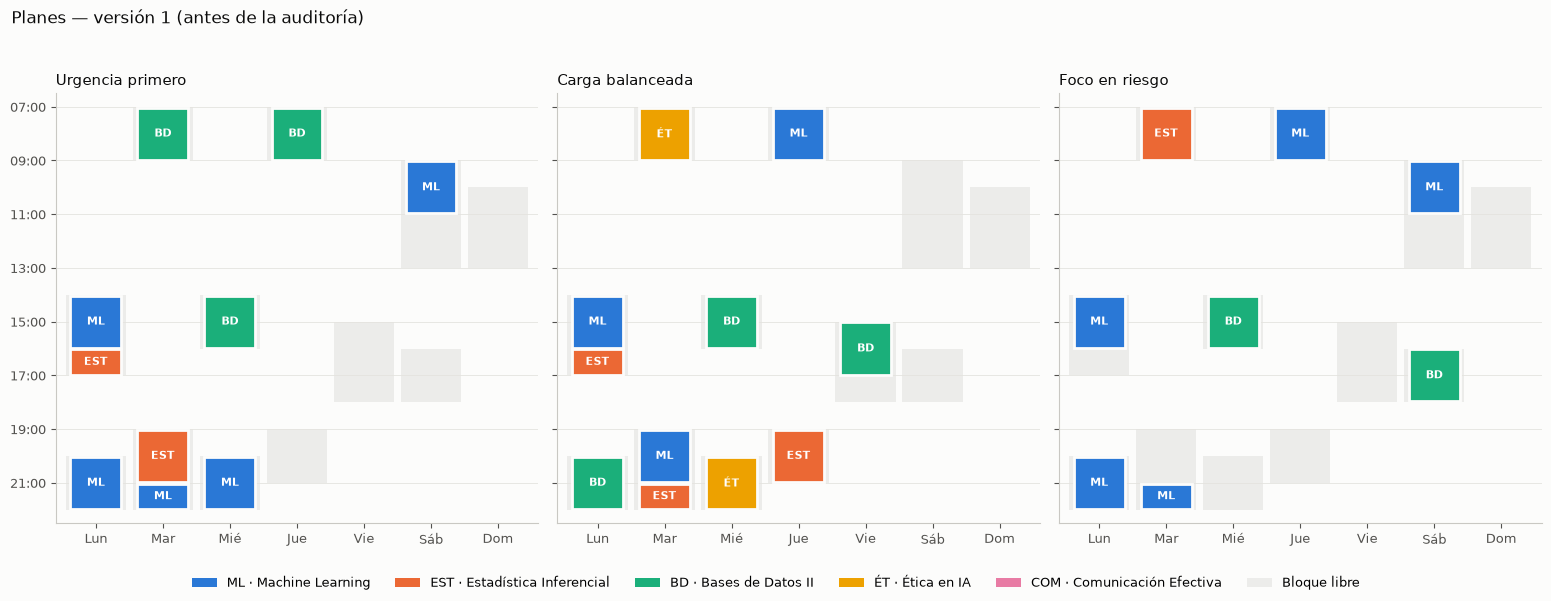

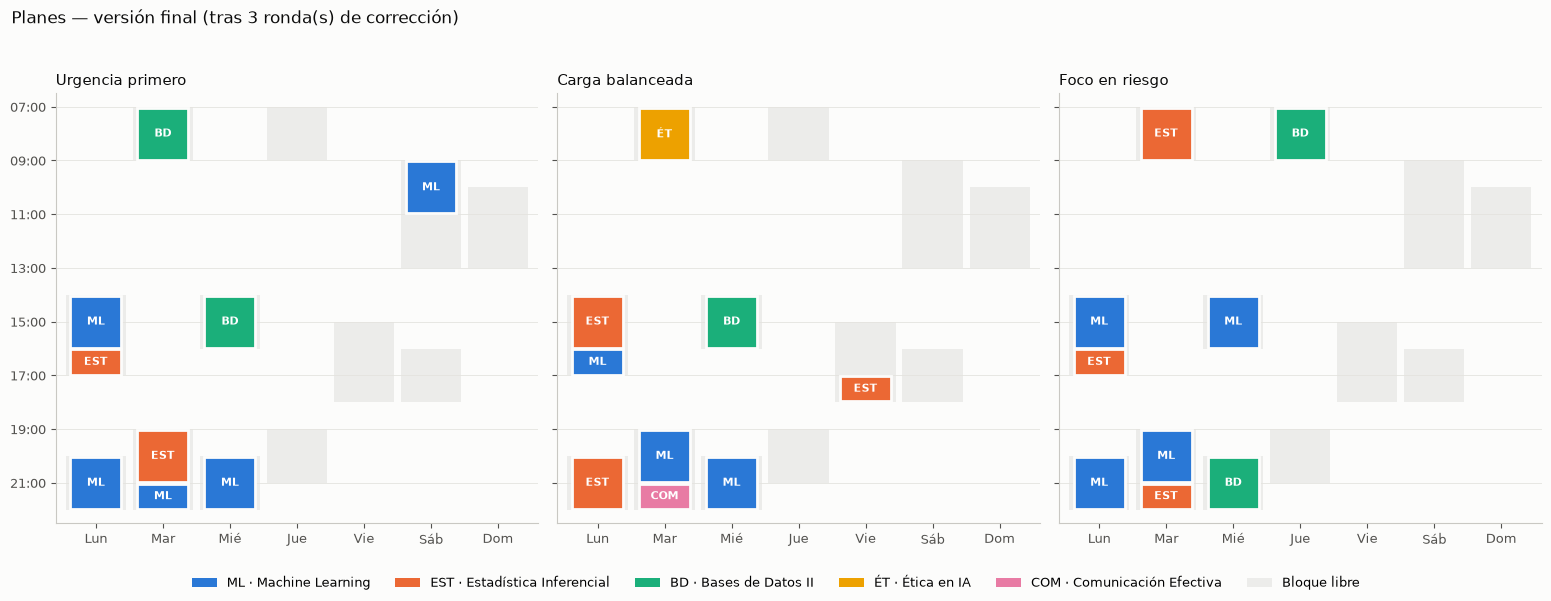

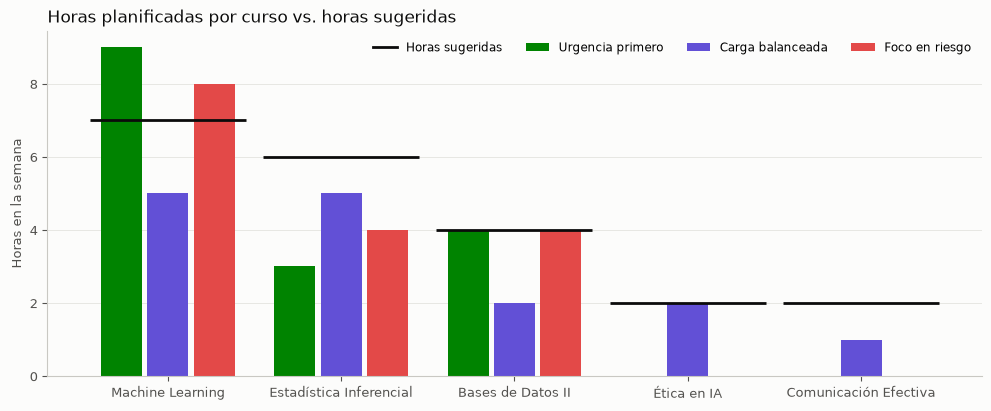

In [16]:
if len(HISTORIAL_PLANES) > 1:
    graficar_calendario(
        HISTORIAL_PLANES[0],
        ESTUDIANTE,
        "Planes — versión 1 (antes de la auditoría)",
        "salidas/calendario_v1.png",
    )
graficar_calendario(
    planes,
    ESTUDIANTE,
    f"Planes — versión final (tras {RONDAS_REALIZADAS} ronda(s) de corrección)",
    "salidas/calendario_final.png",
)
graficar_horas(auditorias, ESTUDIANTE, "salidas/horas_por_curso.png")

### Paso 4 · Agente Evaluador de carga


In [17]:
evaluacion = ejecutar_paso(
    "4. Evaluación",
    tarea_evaluacion,
    {
        "analisis": analisis,
        "planes": planes.model_dump_json(indent=1),
        "reporte": reporte,
        "informe_auditor": informe_auditor,
    },
    modelo=EvaluacionComparativa,
)
guardar("4_evaluacion.json", evaluacion)

for e in evaluacion.evaluaciones:
    display(
        Markdown(
            f"#### {e.plan}\n**Ventajas**\n"
            + "\n".join(f"- {v}" for v in e.ventajas)
            + "\n\n**Desventajas**\n"
            + "\n".join(f"- {d}" for d in e.desventajas)
        )
    )
display(
    Markdown(f"**Comentario general del evaluador:** {evaluacion.comentario_general}")
)

# 4b · Puntaje ponderado calculado en Python (no por el LLM)
tabla_puntajes = puntaje_ponderado(evaluacion, auditorias)
guardar("4b_puntajes.csv", tabla_puntajes.to_csv())
display(
    Markdown(
        "#### Matriz de evaluación y puntaje ponderado (pesos: "
        + ", ".join(f"{c} {w:.0%}" for c, w in CRITERIOS.items())
        + ")"
    )
)
display(tabla_puntajes)

▶ 4. Evaluación [Evaluador de carga académica] intento 1 ... 

✓ 45 s


#### Urgencia primero
**Ventajas**
- Prioriza evaluaciones más cercanas, asegurando cumplimiento de mínimos obligatorios.
- Distribuye el estudio en la mañana para cursos difíciles.

**Desventajas**
- Violaciones duras: Estadística Inferencial y Ética en IA no cumplen con sus mínimos obligatorios.
- Cobertura baja de horas sugeridas, especialmente para Estadística Inferencial.

#### Carga balanceada
**Ventajas**
- Cumple con todas las restricciones duras.
- Distribución equitativa de horas entre los días.

**Desventajas**
- Cobertura baja para Machine Learning, Bases de Datos II y Comunicación Efectiva.
- Ningún curso tiene horas en la mañana, lo que podría afectar el rendimiento.

#### Foco en riesgo
**Ventajas**
- Prioriza cursos con mayor riesgo de desaprobar, asegurando cumplimiento de mínimos obligatorios.
- Distribución equitativa entre los días.

**Desventajas**
- Violaciones duras: Estadística Inferencial y Ética en IA no cumplen con sus mínimos obligatorios.
- Cobertura baja para Machine Learning, Bases de Datos II y Comunicación Efectiva.

**Comentario general del evaluador:** Los planes 'Urgencia primero' y 'Foco en riesgo' priorizan los cursos con mayor riesgo de desaprobar, pero no cumplen con todas las restricciones duras. El plan 'Carga balanceada' cumple con las restricciones duras, pero requiere ajustes para mejorar la cobertura de horas y distribución matutina. Todos los planes podrían beneficiarse de una mayor flexibilidad en el horario y mejor distribución de horas para los cursos más difíciles.

#### Matriz de evaluación y puntaje ponderado (pesos: prioridad_academica 30%, factibilidad 25%, balance_carga 20%, bienestar 15%, preferencias 10%)

,prioridad_academica,factibilidad,balance_carga,bienestar,preferencias,puntaje_ponderado,violaciones_duras
plan,,,,,,,
Carga balanceada,3,4,5,4,2,3.70,0
Urgencia primero,4,2,3,3,3,3.05,2
Foco en riesgo,3,2,3,3,3,2.75,2


### Paso 5 · Agente Decisor (asesor académico)


In [18]:
decision = ejecutar_paso(
    "5. Decisión",
    tarea_decision,
    {
        "analisis": analisis,
        "planes": planes.model_dump_json(indent=1),
        "informe_auditor": informe_auditor,
        "evaluacion": evaluacion.model_dump_json(indent=1),
        "puntajes": tabla_puntajes.to_string(),
    },
)
guardar("5_decision.md", decision)
DURACION_TOTAL = time.time() - INICIO
display(Markdown(decision))

▶ 5. Decisión [Asesor académico (decisor final)] intento 1 ... 

✓ 45 s


PLAN SELECCIONADO: Carga balanceada

## Por qué se seleccionó
El plan "Carga balanceada" fue seleccionado porque cumple con todas las restricciones duras establecidas. Aunque requiere ajustes para mejorar la cobertura de horas y distribución matutina, este plan ofrece una estructura equitativa que permite un mejor manejo del tiempo y reduce el riesgo de sobrecarga durante la semana.

## Criterios que más pesaron
1. **Cumplimiento de restricciones duras**: El plan "Carga balanceada" cumple con todas las restricciones, lo cual es crucial para evitar penalizaciones.
2. **Equilibrio en la carga diaria**: La distribución equitativa de horas entre los días ayuda a mantener un ritmo constante y reduce el riesgo de agotamiento.
3. **Flexibilidad en el horario matutino**: Aunque requiere ajustes, este plan ofrece más flexibilidad para adaptarse a las preferencias del estudiante.

## Riesgos que permanecen
1. **Cobertura baja para Machine Learning y Bases de Datos II**: Ambos cursos tienen cobertura baja en horas sugeridas.
2. **Ningún curso tiene horas en la mañana**: Esto podría afectar el rendimiento, especialmente para los cursos difíciles.

## Recomendaciones para el estudiante
1. **Ajuste de horario matutino**: El estudiante debe priorizar las sesiones matutinas para Machine Learning y Bases de Datos II.
2. **Uso eficiente del tiempo libre**: Utilizar las horas libres en la tarde y noche para complementar el estudio de los cursos con mayor carga.

## Qué debe revisar una persona antes de aplicar el plan
1. **Horas sugeridas por curso**: Verificar que se cumplan al menos el 70% de las horas sugeridas para Machine Learning y Estadística Inferencial, y el 50% para Bases de Datos II.
2. **Fechas límite**: Asegurarse de que todas las sesiones estén programadas antes de la fecha límite correspondiente.

## Horario final (tabla con día, horario, curso y actividad)
| Día       | Horario     | Curso               | Actividad                                      |
|-----------|-------------|---------------------|------------------------------------------------|
| Lunes     | 14:00-16:00 | Estadística Inferencial | Resolver ejercicios de inferencia estadística   |
| Lunes     | 16:00-17:00 | Machine Learning    | Revisar y comprender algoritmos de aprendizaje automático |
| Lunes     | 20:00-22:00 | Estadística Inferencial | Realizar análisis estadísticos con software   |
| Martes    | 07:00-09:00 | Ética en IA         | Leer y discutir artículos sobre ética en inteligencia artificial |
| Martes    | 19:00-21:00 | Machine Learning   | Implementar modelos de aprendizaje automático en código |
| Martes    | 21:00-22:00 | Comunicación Efectiva | Escribir y revisar ensayo sobre comunicación científica |
| Miércoles | 14:00-16:00 | Bases de Datos II   | Realizar consultas SQL en base de datos        |
| Miércoles | 20:00-22:00 | Machine Learning   | Entrenar modelos de aprendizaje automático con datos reales |
| Jueves    | 07:00-09:00 | Bases de Datos II   | Estudiar diseño y normalización de bases de datos |

Este horario final se ajustará según las correcciones propuestas en el informe del auditor para mejorar la cobertura de horas sugeridas.

### Traza de ejecución (evidencia)

Cada fila es una llamada real a un agente. Todas las salidas quedaron guardadas en la carpeta `salidas/`.


In [19]:
df_traza = pd.DataFrame(TRAZA)
display(df_traza)
print(
    f"Proveedor: {PROVEEDOR} | Modelo: {MODELO_OLLAMA if PROVEEDOR == 'ollama' else MODELO_GROQ}"
)
print(
    f"Llamadas a agentes: {len(df_traza)} | Rondas de corrección: {RONDAS_REALIZADAS} | "
    f"Tiempo total: {DURACION_TOTAL / 60:.1f} min"
)
print("Archivos generados:", sorted(p.name for p in SALIDAS.iterdir()))
df_traza.to_csv(SALIDAS / "traza_ejecucion.csv", index=False)

,paso,agente,intento,segundos,tokens_prompt,tokens_respuesta
0,1. Análisis,Analista académico del estudiante,1,22.4,1716,847
1,2. Planificación · Urgencia primero,Diseñador de planes de estudio,1,24.6,3147,547
2,2. Planificación · Carga balanceada,Diseñador de planes de estudio,1,24.3,3153,530
3,2. Planificación · Foco en riesgo,Diseñador de planes de estudio,1,21.6,3150,438
4,3. Auditoría · Urgencia primero,Auditor de factibilidad y restricciones,1,18.1,3058,440
5,3. Auditoría · Carga balanceada,Auditor de factibilidad y restricciones,1,25.7,3133,732
6,3. Auditoría · Foco en riesgo,Auditor de factibilidad y restricciones,1,27.7,2953,699
7,2. Corrección · Urgencia primero,Diseñador de planes de estudio,1,32.3,4362,420
8,2. Corrección · Carga balanceada,Diseñador de planes de estudio,1,36.2,4713,463
9,2. Corrección · Foco en riesgo,Diseñador de planes de estudio,1,32.0,4682,435


Proveedor: ollama | Modelo: qwen2.5-planifica
Llamadas a agentes: 25 | Rondas de corrección: 3 | Tiempo total: 11.8 min
Archivos generados: ['1_analisis.md', '2_planes_v1.json', '2_planes_v2.json', '2_planes_v3.json', '2_planes_v4.json', '3_auditoria_ronda0.md', '3_auditoria_ronda1.md', '3_auditoria_ronda2.md', '3_auditoria_ronda3.md', '4_evaluacion.json', '4b_puntajes.csv', '5_decision.md', 'calendario_final.png', 'calendario_v1.png', 'horas_por_curso.png']


## 6.7 Decisión final

Antes de presentar la decisión, comprobamos con código que sea **consistente** con la evidencia: ¿el plan elegido existe, no tiene violaciones duras y coincide con el mejor puntaje ponderado?


,resultado,detalle
verificación,,
El decisor indicó un plan existente,True,Carga balanceada
El plan elegido no tiene violaciones duras,True,0
Coincide con el mayor puntaje ponderado,True,mejor puntaje: Carga balanceada


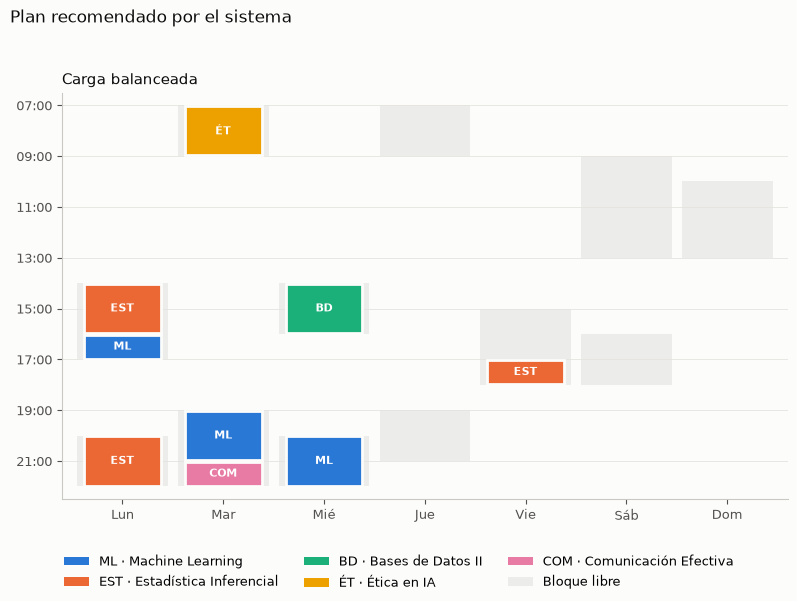

,dia,inicio,fin,curso,actividad
0,Lunes,14:00,16:00,Estadística Inferencial,Resolver ejercicios de inferencia estadística
1,Lunes,16:00,17:00,Machine Learning,Revisar y comprender algoritmos de aprendizaje automático
2,Lunes,20:00,22:00,Estadística Inferencial,Realizar análisis estadísticos con software
3,Martes,07:00,09:00,Ética en IA,Leer y discutir artículos sobre ética en inteligencia artificial
4,Martes,19:00,21:00,Machine Learning,Implementar modelos de aprendizaje automático en código
5,Martes,21:00,22:00,Comunicación Efectiva,Escribir y revisar ensayo sobre comunicación científica
6,Miércoles,14:00,16:00,Bases de Datos II,Realizar consultas SQL en base de datos
7,Miércoles,20:00,22:00,Machine Learning,Entrenar modelos de aprendizaje automático con datos reales
8,Viernes,17:00,18:00,Estadística Inferencial,Realizar simulaciones estadísticas para pruebas de hipótesis


,horas,sugeridas
Machine Learning,5.0,7
Estadística Inferencial,5.0,6
Bases de Datos II,2.0,4
Ética en IA,2.0,2
Comunicación Efectiva,1.0,2


In [20]:
m = re.search(r"PLAN SELECCIONADO:\s*\**\s*(.+)", decision)
elegido_texto = m.group(1).strip(" *`\"'") if m else ""
nombres = [p.nombre for p in planes.planes]
# Empate tolerante entre el texto del decisor y los nombres de los planes
elegido = next(
    (
        n
        for n in nombres
        if _sin_tildes(n) in _sin_tildes(elegido_texto)
        or _sin_tildes(elegido_texto) in _sin_tildes(n)
    ),
    None,
)
plan_final = next((p for p in planes.planes if p.nombre == elegido), None)
auditoria_final = next((a for a in auditorias if a["plan"] == elegido), None)
mejor_puntaje = tabla_puntajes.index[0]

chequeo = pd.DataFrame(
    [
        {
            "verificación": "El decisor indicó un plan existente",
            "resultado": elegido is not None,
            "detalle": elegido_texto,
        },
        {
            "verificación": "El plan elegido no tiene violaciones duras",
            "resultado": bool(auditoria_final)
            and not auditoria_final["violaciones_duras"],
            "detalle": (
                len(auditoria_final["violaciones_duras"]) if auditoria_final else "—"
            ),
        },
        {
            "verificación": "Coincide con el mayor puntaje ponderado",
            "resultado": elegido == mejor_puntaje,
            "detalle": f"mejor puntaje: {mejor_puntaje}",
        },
    ]
).set_index("verificación")
display(chequeo)

if plan_final:
    graficar_calendario(
        PlanesSemanales(planes=[plan_final]),
        ESTUDIANTE,
        "Plan recomendado por el sistema",
        "salidas/plan_recomendado.png",
    )
    df_final = pd.DataFrame([s.model_dump() for s in plan_final.sesiones])
    df_final["orden"] = df_final.dia.map(DIAS.index)
    display(
        df_final.sort_values(["orden", "inicio"])
        .drop(columns="orden")
        .reset_index(drop=True)
    )
    display(
        pd.Series(auditoria_final["horas_por_curso"], name="horas")
        .to_frame()
        .assign(sugeridas=[c["horas_sugeridas"] for c in ESTUDIANTE["cursos"]])
    )

### Análisis de la decisión

> **Nota:** este análisis corresponde a la ejecución entregada (Ollama · `qwen2.5:7b`). Los LLM no son deterministas: si se vuelve a ejecutar el notebook, los planes y los puntajes pueden variar.

**Alternativa seleccionada:** plan **«Carga balanceada»**: 9 sesiones, 15 h, de lunes a viernes.

| Curso                   | Horas en el plan | Mínimo obligatorio | Horas sugeridas | Evaluación                      |
| ----------------------- | ---------------- | ------------------ | --------------- | ------------------------------- |
| Machine Learning        | 5                | 5                  | 7               | Parcial, lunes 19/10            |
| Estadística Inferencial | 5                | 4.5                | 6               | Proyecto, viernes 16/10         |
| Bases de Datos II       | 2                | 2                  | 4               | Laboratorio, jueves 15/10 10:00 |
| Ética en IA             | 2                | 1                  | 2               | Control, martes 13/10 11:00     |
| Comunicación Efectiva   | 1                | 0                  | 2               | Ensayo, miércoles 21/10         |

**¿Por qué fue seleccionada?** Es el **único plan que terminó el bucle sin violaciones duras** (APTO desde la ronda 2). «Urgencia primero» y «Foco en riesgo» quedaron con 2 violaciones cada uno: Ética en IA sin horas antes del control del martes y Estadística por debajo de su mínimo. El decisor aplicó su regla ("nunca elegir un plan con violaciones duras si existe uno apto") y su elección **coincide con el mayor puntaje ponderado** (3.70 frente a 3.05 y 2.75). Las tres verificaciones de consistencia de la celda anterior salen en verde.

**¿Qué criterios pesaron más?** **Factibilidad** (4 frente a 2) y **balance de carga** (5 frente a 3). Los planes alternativos le daban más horas a Machine Learning (8–9 h), pero a costa de dejar sin preparación el control de Ética y el proyecto de Estadística. El sistema prefirió **cubrir todas las evaluaciones de la semana en el orden correcto** (Ética el martes antes del control, Bases de Datos el miércoles antes del laboratorio, Estadística entre lunes y viernes) antes que maximizar el curso más riesgoso.

**¿Qué riesgos permanecen?**

- **Machine Learning** (nota 11, dificultad 5, el curso con mayor riesgo) queda justo en su mínimo de 5 h, 2 h por debajo de lo sugerido, con el parcial el lunes 19.
- Es un plan **conservador**: usa 15 de las 30 h libres y deja jueves, sábado y domingo sin estudio. Además, 0 % de las horas de cursos difíciles caen en la mañana (preferencia no atendida).
- Bases de Datos II queda con 2 h (su mínimo) antes del laboratorio.
- **El texto del decisor tiene imprecisiones:** su tabla "Horario final" incluye una sesión de Bases de Datos el jueves 07:00 que **no existe** en el plan validado y omite la de Estadística del viernes 17:00; también afirma que "ningún curso tiene horas en la mañana", cuando Ética sí las tiene. Por eso el horario oficial que mostramos es el que sale del **JSON validado**, no el texto del LLM.

**¿Qué debería revisar una persona antes de aplicarlo?**

1. Que los datos de entrada sean correctos: fechas, horas sugeridas y bloques libres (ver el experimento de la sección 6.8).
2. Si conviene usar las franjas libres del fin de semana para Machine Learning (ver el ajuste propuesto a continuación).
3. Que las actividades correspondan al temario real del curso (el LLM las redacta de forma genérica).
4. Si el lunes y el martes, con 5 h de estudio cada uno (el máximo permitido), son sostenibles.

#### Ajuste humano propuesto (humano en el circuito)

Un tutor que revise el plan probablemente agregaría Machine Learning el **sábado por la mañana** (franjas F13 y F14, libres y permitidas), lo que además atiende la preferencia de estudiar los cursos difíciles en la mañana. Antes de aplicar el cambio, lo pasamos por el **mismo verificador**: el sistema también sirve para validar las decisiones humanas.


In [21]:
if plan_final:
    ajustado = plan_final.model_copy(deep=True)
    ajustado.nombre = f"{plan_final.nombre} + ajuste humano"
    ajustado.sesiones += [
        Sesion(
            dia="Sábado",
            inicio="09:00",
            fin="11:00",
            curso="Machine Learning",
            actividad="Simulacro de examen parcial con problemas tipo",
        ),
        Sesion(
            dia="Sábado",
            inicio="11:00",
            fin="13:00",
            curso="Machine Learning",
            actividad="Revisar los errores del simulacro y repasar teoría",
        ),
    ]
    comparacion = [
        auditar_plan(plan_final, ESTUDIANTE),
        auditar_plan(ajustado, ESTUDIANTE),
    ]
    display(tabla_auditoria(comparacion))
    display(
        Markdown(
            "**Observaciones del verificador sobre el plan ajustado:**\n"
            + (
                "\n".join(f"- {o}" for o in comparacion[1]["observaciones"])
                or "- ninguna"
            )
        )
    )

,horas totales,violaciones duras,observaciones,desbalance diario (h),% difíciles en mañana,h Machine Learning,h Estadística Inferencial,h Bases de Datos II,h Ética en IA,h Comunicación Efectiva
plan,,,,,,,,,,
Carga balanceada,15.0,0,4,1.64,0%,5.0,5.0,2.0,2.0,1.0
Carga balanceada + ajuste humano,19.0,0,3,1.47,29%,9.0,5.0,2.0,2.0,1.0


**Observaciones del verificador sobre el plan ajustado:**
- Cobertura baja: Bases de Datos II 2.0 h de 4 h sugeridas
- Cobertura baja: Comunicación Efectiva 1.0 h de 2 h sugeridas
- Solo 29% de las horas de cursos difíciles son en la mañana

## 6.8 Evaluación crítica

### Experimento: ¿qué pasa si los datos son incompletos o incorrectos?

Para responder con evidencia y no solo con opinión, corrompemos el perfil a propósito:

1. **Dato faltante:** eliminamos la disponibilidad del sábado y la nota actual de Machine Learning.
2. **Dato incorrecto:** las horas sugeridas de Estadística pasan de 6 a 60 (error de tipeo).
3. **Dato inconsistente:** el control de Ética figura el martes, pero su fecha límite dice domingo.

Luego (a) pasamos el perfil corrupto por el **Analista** para ver si detecta los problemas y (b) auditamos el **plan recomendado** con el verificador usando los datos corruptos.


In [22]:
import copy

CORRUPTO = copy.deepcopy(ESTUDIANTE)
CORRUPTO["disponibilidad"]["Sábado"] = []  # el estudiante "olvidó" llenar el sábado
CORRUPTO["cursos"][0]["nota_actual"] = None  # nota de ML faltante
CORRUPTO["cursos"][1]["horas_sugeridas"] = 60  # error de tipeo (6 -> 60)
CORRUPTO["cursos"][3]["fecha_limite"] = {
    "dia": "Domingo",
    "hora": "23:59",
}  # inconsistente con "martes"

analisis_corrupto = paso_analisis(CORRUPTO)
guardar("6_analisis_datos_corruptos.md", analisis_corrupto)
display(Markdown(analisis_corrupto))

▶ 1. Análisis [Analista académico del estudiante] intento 1 ... 

✓ 34 s


```markdown
# Resumen Estructurado

## 1. Situación general
- **Carrera:** Ciencia de Datos e IA, 5º ciclo
- **Semana analizada:** Lunes 12 al domingo 18 de octubre de 2026 (semana 9)
- **Comparación entre horas sugeridas totales y horas libres:**
  - Horas sugeridas totales: 75
  - Horas libres totales: 24

## 2. Cursos ordenados por prioridad calculada, con nivel de riesgo (alto/medio/bajo) y horas sugeridas
| Curso                     | Prioridad Estudiante | Dificultad | Proxima Evaluación          | Fecha Limite       | Nota Actual | Horas Sugeridas | Nivel de Riesgo |
|---------------------------|---------------------|------------|----------------------------|--------------------|-------------|-----------------|----------------|
| Machine Learning           | Alta                | 5          | Examen parcial el lunes 19/10 | No aplicable       | Sin nota    | 7               | Alto            |
| Estadística Inferencial   | Alta                | 4          | Proyecto el viernes 16/10 a las 23:59 | Viernes, 16/10     | 13          | 60              | Alto            |
| Bases de Datos II          | Media               | 3          | Laboratorio calificado el jueves 15/10 a las 10:00 | Jueves, 15/10     | 15          | 4               | Medio           |
| Ética en IA                | Media               | 2          | Control de lectura el martes 13/10 a las 11:00 | Domingo, 18/10   | 14          | 2               | Bajo            |
| Comunicación Efectiva      | Baja                | 2          | Ensayo el miércoles 21/10 (semana siguiente)    | No aplicable       | 16          | 2               | Bajo            |

## 3. Disponibilidad real
- **Horas libres por día:**
  - Lunes: 5.0 horas
  - Martes: 5.0 horas
  - Miércoles: 4.0 horas
  - Jueves: 4.0 horas
  - Viernes: 3.0 horas
  - Sábado: 0.0 horas
  - Domingo: 3.0 horas

- **Horas libres totales:** 24.0 horas

## 4. Restricciones duras y preferencias
- **Restricciones duras:**
  1. Solo puede estudiar dentro de los bloques de disponibilidad indicados.
  2. Máximo 5 horas de estudio por día.
  3. No estudiar después de las 22:00.
  4. El estudio de un curso debe terminar antes de su evaluación (fecha_limite).
  5. Los cursos con prioridad alta deben recibir al menos el 70% de sus horas sugeridas, y los que tienen evaluación esta semana al menos el 50%.

- **Preferencias:**
  1. Rinde mejor en la mañana: preferiría estudiar los cursos difíciles (dificultad 4-5) antes de las 13:00.
  2. Sesiones de máximo 2 horas seguidas del mismo curso.
  3. Quiere al menos un bloque libre el fin de semana para descansar.

## 5. Fechas límite que condicionan el orden del estudio
- **Machine Learning:** Examen parcial el lunes 19/10 (semana siguiente).
- **Estadística Inferencial:** Proyecto a entregar el viernes 16/10 a las 23:59.
- **Bases de Datos II:** Laboratorio calificado el jueves 15/10 a las 10:00.

## 6. Datos faltantes, inconsistentes o supuestos que estás asumiendo
- **Machine Learning:** La nota actual es nula, lo cual implica un alto riesgo.
- **Comunicación Efectiva:** No tiene fecha de entrega, por lo que no se incluye en las restricciones de estudio.
- **Horas sugeridas para Machine Learning y Estadística Inferencial:** Se asumen como necesarias dada la prioridad alta del estudiante.

Estos datos son esenciales para planificar la semana de Andrea, asegurando que se cumplan los objetivos académicos y se respeten las restricciones y preferencias.
```

In [23]:
if plan_final:
    a_ok = auditar_plan(plan_final, ESTUDIANTE)
    a_mal = auditar_plan(plan_final, CORRUPTO)
    display(
        pd.DataFrame(
            {
                "datos correctos": [
                    len(a_ok["violaciones_duras"]),
                    len(a_ok["observaciones"]),
                    a_ok["cobertura"]["Estadística Inferencial"],
                ],
                "datos corruptos": [
                    len(a_mal["violaciones_duras"]),
                    len(a_mal["observaciones"]),
                    a_mal["cobertura"]["Estadística Inferencial"],
                ],
            },
            index=["violaciones duras", "observaciones", "cobertura Estadística"],
        )
    )
    display(
        Markdown(
            "**Violaciones que aparecen con los datos corruptos:**\n"
            + "\n".join(
                f"- {v}"
                for v in a_mal["violaciones_duras"]
                if v not in a_ok["violaciones_duras"]
            )
        )
    )

,datos correctos,datos corruptos
violaciones duras,0.00,1.00
observaciones,4.00,4.00
cobertura Estadística,0.83,0.08


**Violaciones que aparecen con los datos corruptos:**
- Curso por debajo de su mínimo obligatorio: Estadística Inferencial 5.0 h (mínimo 42 h, sugeridas 60 h)

### Resultado del experimento con datos corruptos

| Problema introducido                                                        | ¿Lo detectó el Analista (LLM)?                                   | ¿Lo detectó el Verificador (Python)?                                                                      |
| --------------------------------------------------------------------------- | ---------------------------------------------------------------- | --------------------------------------------------------------------------------------------------------- |
| Nota de Machine Learning faltante                                           | ✅ Sí ("la nota actual es nula, lo cual implica un alto riesgo") | — (el verificador no usa la nota)                                                                         |
| Horas sugeridas de Estadística: 6 → 60                                      | ❌ No: copió "60" en su tabla sin cuestionarlo                   | ✅ Indirectamente: el plan pasa de 0 a 1 violación (Estadística con 8 % de cobertura)                     |
| Sábado sin disponibilidad                                                   | ❌ No: lo listó con 0 h sin comentarlo                           | ⚠️ No en este caso, porque el plan recomendado no usa el sábado (sí bloquearía cualquier plan que lo use) |
| Fecha de Ética inconsistente (control el martes, `fecha_limite` el domingo) | ❌ No: reprodujo ambas fechas                                    | ❌ No: el verificador confía en `fecha_limite`                                                            |

**Conclusión:** el sistema sigue el principio _garbage in, garbage out_. El analista LLM **no es un validador de datos confiable** (detectó 1 de 4 problemas) y el verificador solo comprueba que el plan cumpla las reglas, **no que los datos sean verdaderos**.

### Comparación con la primera versión del sistema

Antes de llegar al diseño actual ejecutamos una primera versión (evidencia en `evidencia_v1_diseno_inicial/`) en la que el planificador escribía las horas libremente y generaba los 3 planes en una sola llamada, con un solo auditor para todos.

|                                           | Versión 1                                                                                                        | Versión final                                                             |
| ----------------------------------------- | ---------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------- |
| Cómo planifica el LLM                     | Inventa día y hora de cada sesión                                                                                | Asigna cursos a franjas válidas precalculadas                             |
| Retroalimentación al planificador         | Informe del auditor (genérico, de los 3 planes)                                                                  | Violaciones + **sugerencias concretas** + informe del auditor de ese plan |
| Horas por plan al final                   | 6 – 9.5 h (de 21 sugeridas)                                                                                      | 15 – 16 h                                                                 |
| Violaciones duras (ronda inicial → final) | 8 → 6                                                                                                            | 8 → 4                                                                     |
| Planes APTOS al final                     | 0 de 3                                                                                                           | 1 de 3                                                                    |
| Plan recomendado                          | **Con 2 violaciones duras** (Estadística con 0 h a 4 días de la entrega; Bases de Datos después del laboratorio) | Sin violaciones duras                                                     |
| Llamadas a agentes · tiempo               | 9 · 9.6 min                                                                                                      | 25 · 11.8 min                                                             |

**Lección:** el mayor salto de calidad no vino de usar un modelo más grande (probamos uno de 14B con resultados similares), sino de **cambiar la interfaz entre el LLM y el problema**: menos libertad donde el LLM es débil (aritmética de horarios) y más contexto calculado por código.

### Respuestas a las preguntas de evaluación crítica

**¿La decisión fue razonable?**
Parcialmente. Es **factible y prudente**: cumple todas las restricciones duras y prepara cada evaluación de la semana antes de su fecha. Pero es **conservadora**: deja Machine Learning (el curso en mayor riesgo) en su mínimo y no usa el fin de semana. Un tutor probablemente aplicaría el ajuste del sábado, que el verificador confirma como válido. Además, la convergencia no está garantizada: **2 de los 3 planes no lograron corregirse en 3 rondas** (el modelo de 7B repetía la misma asignación aunque recibiera la sugerencia exacta). Con un solo plan apto, la comparación entre alternativas pierde fuerza.

**¿Qué errores podría cometer el sistema?** (todos observados en nuestras ejecuciones)

- **Analista:** marcó como "dato faltante" la fecha del parcial de Machine Learning (sí está: lunes 19/10) y omitió Comunicación Efectiva en la sección de fechas límite. En la versión 1, además, sumó mal las horas libres.
- **Planificador:** ignora parte de la retroalimentación, le da demasiadas horas al curso de su enfoque y redacta actividades genéricas.
- **Decisor:** inventó una sesión en su tabla de horario final y afirmó cosas imprecisas sobre las mañanas.
- **Evaluador:** sus puntajes de 1 a 5 son juicios del LLM; no son exactamente reproducibles entre ejecuciones.
- **Del sistema en general:** no determinismo; pesos de los criterios definidos por nosotros (otro estudiante podría priorizar distinto); no conoce información que no esté en los datos (cansancio, tareas imprevistas, tiempo real de traslado).

**¿Qué pasaría si los datos fueran incompletos o incorrectos?**
Como mostró el experimento: el sistema **generaría un plan con apariencia profesional pero basado en datos erróneos**. Un error de tipeo (60 h) distorsiona los mínimos obligatorios; una fecha inconsistente puede programar estudio después de una evaluación; un día sin disponibilidad declarada se interpreta como "no hay tiempo" en lugar de "falta el dato". Los LLM tienden a **reproducir los datos en lugar de cuestionarlos**.

**¿Dónde debería intervenir una persona?**

1. **Antes del flujo:** confirmar los datos de entrada (cursos, fechas, horas, disponibilidad).
2. **En los criterios:** los pesos (30/25/20/15/10) reflejan valores; el estudiante debería poder ajustarlos.
3. **Después de la decisión:** aprobar o ajustar el plan (como el ajuste del sábado) y volver a verificarlo.
4. **Si ningún plan es APTO:** el sistema debería escalar el caso a un tutor en lugar de recomendar un plan infactible.
5. **Durante la semana:** volver a planificar si algo cambia (enfermedad, nueva tarea, cambio de fecha).

**¿Qué mejoraríamos en una siguiente versión?**

- **Validación de datos de entrada** con Pydantic (rangos de horas, coherencia entre `proxima_evaluacion` y `fecha_limite`, cada día con disponibilidad declarada explícitamente) antes de llamar al analista.
- **Reparación determinista como respaldo:** si tras N rondas un plan sigue con violaciones, aplicar automáticamente las sugerencias ya calculadas y marcarlo como "reparado".
- **Solver + LLM:** generar la asignación de franjas con un optimizador (programación lineal, OR-Tools) y usar el LLM para personalizar actividades y explicar la decisión.
- **Comparar proveedores:** ejecutar el mismo flujo con Groq (`llama-3.3-70b-versatile`) y medir la convergencia frente al modelo local de 7B.
- **CrewAI Flows y guardrails:** formalizar el bucle con estado tipado y validar la salida del planificador con `guardrail` en la tarea.
- **Horario final generado por código** a partir del JSON validado; el decisor solo justificaría (evita la alucinación observada).
- **Retroalimentación real:** registrar qué se cumplió cada semana y ajustar las horas sugeridas.


## 6.9 Crew secuencial de una pasada: cinco agentes y cinco tareas


In [ ]:
crew_estudio = Crew(
    agents=AGENTES,
    tasks=[
        tarea_analisis(),
        tarea_planificacion(),
        tarea_auditoria(),
        tarea_evaluacion(),
        tarea_decision(),
    ],
    process=Process.sequential,
    verbose=False,
)

resultado_crew_estudio = await crew_estudio.kickoff_async(
    inputs={"perfil_estudiante": perfil_para_agentes(ESTUDIANTE)}
)